# Ćwiczenie O18 — Bodo: analiza danych
## Badanie zjawiska dyfrakcji i interferencji światła laserowego

Notebook obliczeniowy do sprawozdania `bodo.tex`. Surowe dane zebrał `bodo_pomiary.ipynb`:
`red/` i `green/` — przejazdy skanera (`t,x,I`: czas [s], położenie [mm], natężenie [%]) i rejestr `scans.csv`
z parametrami układu.

Każdą wielkość ($a$, $d$) wyznaczono **dwiema metodami**:

1. **dopasowanie krzywej** — model natężenia (wzór 4.12.20 skryptu) dopasowany do całego rozkładu $I(x)$
   funkcją `scipy.optimize.curve_fit`;
2. **regresja liniowa** — położenia minimów dyfrakcyjnych (lub maksimów interferencyjnych) w funkcji ich rzędu,
   $x_m = x_0 + \dfrac{\lambda D}{a}\,m$; z nachylenia $a$ (lub $d$).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import curve_fit
from scipy.stats import linregress
import locale

plt.rcParams.update({'figure.dpi': 150, 'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.3})
plt.rcParams['pdf.fonttype'] = 42   # czcionki TrueType w PDF — poprawne odstępy w obróconych etykietach
locale.setlocale(locale.LC_NUMERIC, 'pl_PL.UTF-8')
plt.rcParams['axes.formatter.use_locale'] = True

def pl(x, spec):
    '''Liczba z przecinkiem dziesiętnym — do legend i opisów na wykresach.'''
    return format(x, spec).replace('.', ',')

def plm(x, spec='.2f'):
    '''Liczba z przecinkiem dziesiętnym w trybie matematycznym (LaTeX i mathtext): 0{,}02 bez odstępu.'''
    return format(x, spec).replace('.', '{,}')

KOLOR = {'red': 'tab:red', 'green': 'tab:green'}
NAZWA = {'red': 'czerwony', 'green': 'zielony'}

### Stałe i dane

Długości fal z tabliczek laserów PASCO: czerwony 650 nm, zielony 515 nm. Tabliczki nie podają tolerancji;
przyjęto $u_\lambda = 5$ nm — typową tolerancję laserów diodowych (np. 3B Scientific U22000: $650 \pm 5$ nm).
Skrypt podaje dla lasera czerwonego 640 nm. Odległość szczelina–detektor z położeń na ławie: szczeliny 20 cm, detektor 110 cm, każde $\pm 1$ cm, więc
$D = (900 \pm 14)$ mm. W części D (zmiana odległości) $D$ jest wpisane w rejestrze przy każdym przejeździe.

Z rejestru brany jest ostatni wpis dla każdego pliku (wcześniejsze dotyczą przerwanych przejazdów
zapisanych pod tą samą nazwą).

In [2]:
LAMBDA = {'red': (650e-6, 5e-6), 'green': (515e-6, 5e-6)}   # [mm], tabliczki laserów; u — typowa tolerancja diody

def rejestr(laser):
    return pd.read_csv(Path(laser) / 'scans.csv').drop_duplicates('file', keep='last').set_index('file')

REJ = {L: rejestr(L) for L in LAMBDA}

# Kalibracja skali x: biblioteka pasco liczy 0,01 m na 2000 impulsów enkodera, ale pełny przesuw głowicy
# (155 mm wg specyfikacji PASCO OS-8441) zapisuje się jako ok. 85 mm. Najdłuższy przejazd (ogranicznik–ogranicznik)
# wyznacza zarejestrowany pełny przesuw; u: 1 mm dla specyfikacji (ostatnia cyfra), 0,5 mm dla L_rej.
PRZESUW, U_PRZESUW = 155.0, 1.0
zakresy = {f'{L}/{p.name}': np.ptp(pd.read_csv(p)['x']) for L in LAMBDA for p in Path(L).glob('*.csv') if p.name != 'scans.csv'}
zakresy = pd.Series(zakresy).sort_values(ascending=False)
L_REJ, U_L_REJ = zakresy.iloc[0], 0.5
SKALA_X = PRZESUW / L_REJ
U_SKALA_X = SKALA_X * np.hypot(U_PRZESUW / PRZESUW, U_L_REJ / L_REJ)
print('najdłuższe przejazdy [mm, skala biblioteki]:'); print(zakresy.head(8).round(2).to_string())
print(f'SKALA_X = {PRZESUW:.0f} / {L_REJ:.2f} = {SKALA_X:.4f} ± {U_SKALA_X:.4f}  ({100 * U_SKALA_X / SKALA_X:.2f} %)')

def wczytaj(laser, plik):
    '''Przejazd posortowany po x; atrybuty: D, u_D, laser, lambda, u_lambda.'''
    df = pd.read_csv(Path(laser) / plik).sort_values('x').reset_index(drop=True)
    df['x'] *= SKALA_X                         # skalibrowane położenie [mm]
    r = REJ[laser].loc[plik]
    df.attrs.update(D=float(r['D']) if pd.notna(r['D']) else np.nan, u_D=float(r['u_D']) if pd.notna(r['u_D']) else np.nan,
                    laser=laser, lam=LAMBDA[laser][0], u_lam=LAMBDA[laser][1], plik=plik)
    return df

for L in LAMBDA:
    t = wczytaj(L, 'background.csv')
    print(f'tło ({NAZWA[L]}): I_tło = {t["I"].mean():.3f} %, σ = {t["I"].std():.3f} %  ({len(t)} pkt)')

najdłuższe przejazdy [mm, skala biblioteki]:
red/single_slit_a02_D500.csv       85.78
red/single_slit_a02_D1000.csv      85.40
red/double_slit_a08_d50_1.csv      84.85
red/single_slit_a02_D400.csv       84.82
red/background.csv                 84.68
red/double_slit_a04_d50_1.csv      84.48
green/double_slit_a08_d25_1.csv    84.48
green/background.csv               84.32
SKALA_X = 155 / 85.78 = 1.8071 ± 0.0157  (0.87 %)
tło (czerwony): I_tło = 0.624 %, σ = 0.019 %  (1500 pkt)
tło (zielony): I_tło = 0.561 %, σ = 0.008 %  (1620 pkt)


### Zestawienie przejazdów (do sekcji Wyniki)

Dla każdego przejazdu: liczba punktów $n$, zakres położeń na skali skanera, czas przejazdu $T$, średnia prędkość
$\bar v = \Delta x / T$, częstość odczytu $f = n/T$ i największe natężenie $I_\text{max}$. Kierunek: → rosnące $x$,
← malejące. Komórka wypisuje gotowe wiersze tabeli LaTeX.

In [3]:
OPISY = [
    ('background.csv', 'tło'),
    *[(f'single_slit_a{a:02d}_{k}.csv', f'1 szczelina, $a = {plm(a / 100)}$') for a in (2, 4, 8, 16) for k in (1, 2, 3)],
    *[(f'double_slit_a{a:02d}_d{d:02d}_{k}.csv', f'2 szczeliny, $a = {plm(a / 100)}$, $d = {plm(d / 100)}$')
      for a in (4, 8) for d in (25, 50) for k in (1, 2, 3)],
    *[(f'multi_slit_N{N}_{k}.csv', f'$N = {N}$') for N in (2, 3, 4, 5) for k in (1, 2, 3)],
    *[(f'single_slit_a02_D{D}.csv', f'1 szczelina, $a = 0{{,}}02$, $D = {D}$') for D in (1000, 500, 400)],
    *[(f'single_slit_a02_aperture_{ap}.csv', f'1 szczelina, $a = 0{{,}}02$, apertura {ap[0]},{ap[1]}') for ap in ('01', '15')],
]

def zestawienie(laser):
    wiersze = []
    for plik, opis in OPISY:
        if plik not in REJ[laser].index:
            continue
        df = pd.read_csv(Path(laser) / plik)
        df['x'] *= SKALA_X
        r = REJ[laser].loc[plik]
        T = df['t'].iloc[-1] - df['t'].iloc[0]
        wiersze.append(dict(plik=plik, opis=opis, kier='→' if r['direction'] > 0 else '←', n=len(df),
                            x_min=df['x'].min(), x_max=df['x'].max(), T=T, v=np.ptp(df['x']) / T, f=len(df) / T,
                            I_max=df['I'].max()))
    return pd.DataFrame(wiersze)

for L in LAMBDA:
    z = zestawienie(L)
    print(f'=== {NAZWA[L]}: {len(z)} przejazdów, f = {z["f"].min():.1f}–{z["f"].max():.1f} pkt/s, '
          f'v = {z["v"].min():.2f}–{z["v"].max():.2f} mm/s')
    for r in z.itertuples():
        kier = '$\\rightarrow$' if r.kier == '→' else '$\\leftarrow$'
        print(f'{r.opis} & {kier} & {r.n} & {r.x_min:.1f} & {r.x_max:.1f} & {r.T:.0f} & {r.v:.2f} & {r.I_max:.2f} \\\\')

=== czerwony: 42 przejazdów, f = 7.0–7.2 pkt/s, v = 0.35–8.37 mm/s
tło & $\rightarrow$ & 1500 & -0.2 & 152.8 & 215 & 0.71 & 0.73 \\
1 szczelina, $a = 0{,}02$ & $\rightarrow$ & 177 & -64.2 & 86.7 & 25 & 6.00 & 2.30 \\
1 szczelina, $a = 0{,}02$ & $\leftarrow$ & 126 & -64.5 & 80.5 & 18 & 8.13 & 2.24 \\
1 szczelina, $a = 0{,}02$ & $\rightarrow$ & 124 & -57.4 & 87.7 & 17 & 8.37 & 2.23 \\
1 szczelina, $a = 0{,}04$ & $\leftarrow$ & 383 & -59.9 & 90.5 & 54 & 2.78 & 7.71 \\
1 szczelina, $a = 0{,}04$ & $\rightarrow$ & 245 & -55.8 & 91.6 & 34 & 4.29 & 9.17 \\
1 szczelina, $a = 0{,}04$ & $\leftarrow$ & 219 & -62.0 & 87.8 & 31 & 4.83 & 9.99 \\
1 szczelina, $a = 0{,}08$ & $\leftarrow$ & 358 & -73.8 & 67.0 & 51 & 2.76 & 29.92 \\
1 szczelina, $a = 0{,}08$ & $\rightarrow$ & 413 & -69.7 & 78.0 & 59 & 2.52 & 33.62 \\
1 szczelina, $a = 0{,}08$ & $\leftarrow$ & 381 & -73.0 & 74.6 & 54 & 2.73 & 35.25 \\
1 szczelina, $a = 0{,}16$ & $\rightarrow$ & 772 & -9.3 & 141.6 & 109 & 1.39 & 47.79 \\
1 szczelina, $a = 

### Modele natężenia

Z oznaczeniem $y = x - C$ ($C$ — środek obrazu na skali skanera) i parametrami
$B_a = \dfrac{\pi a}{\lambda D}$, $B_d = \dfrac{\pi d}{\lambda D}$ [mm$^{-1}$]:

- pojedyncza szczelina: $I = A\,\left[\dfrac{\sin(B_a y)}{B_a y}\right]^2 + b$,
- $N$ szczelin: $I = A\,\left[\dfrac{\sin(N B_d y)}{N \sin(B_d y)}\right]^2 \left[\dfrac{\sin(B_a y)}{B_a y}\right]^2 + b$
  (dla $N = 2$ pierwszy czynnik to $\cos^2(B_d y)$),

gdzie $A$ — natężenie maksimum centralnego, $b$ — stałe tło. Stąd $a = B_a \lambda D/\pi$, $d = B_d \lambda D/\pi$.

**Niepewności z dopasowania.** Niepewność pojedynczego odczytu $I$ nie jest znana (szum czujnika to tylko część
rozrzutu; dochodzą drgania wiązki i niedokładne dopasowanie modelu), dlatego dopasowanie jest nieważone
(`absolute_sigma=False`): macierz kowariancji jest skalowana przez wariancję residuów, czyli niepewność
punktu przyjmuje się równą RMS residuów, $u_{B} = \sqrt{C_{BB}}$.

Dopasowanie startuje z kilku wartości $B_a$ (i $C$) i wybiera to o najmniejszej sumie kwadratów residuów —
funkcja $\mathrm{sinc}^2$ ma wiele minimów lokalnych. Dla wielu szczelin $C$ startuje także o jeden i dwa prążki
obok najwyższego punktu: najwyższy punkt nie musi leżeć na prążku centralnym (np. $N = 2$, przejazd 1 —
bez tego model był przesunięty o jeden prążek).

Residua sąsiednich punktów są skorelowane (punkty gęste względem struktury, residua systematyczne), więc
$u_B$ z macierzy kowariancji jest zaniżone. Rzeczywisty rozrzut pojedynczego przejazdu ocenia się z powtórzeń
(wynik końcowy z trzech przejazdów korzysta tylko z ich rozrzutu).

In [4]:
def sinc2(u):
    return np.sinc(u / np.pi) ** 2

def model_1(x, A, Ba, C, b):
    return A * sinc2(Ba * (x - C)) + b

def model_N(N):
    def f(x, A, Ba, Bd, C, b):
        y = x - C
        s = np.sin(Bd * y)
        with np.errstate(invalid='ignore', divide='ignore'):
            interf = np.where(np.abs(s) < 1e-9, 1.0, (np.sin(N * Bd * y) / (N * s)) ** 2)
        return A * interf * sinc2(Ba * y) + b
    return f

def fwhm(x, I):
    '''Szerokość połówkowa najwyższego maksimum (do wartości startowych).'''
    i0 = np.argmax(I)
    pol = I.min() + (I[i0] - I.min()) / 2
    lewo = np.where(I[:i0] < pol)[0]
    prawo = np.where(I[i0:] < pol)[0]
    return x[i0 + prawo[0]] - x[lewo[-1]] if len(lewo) and len(prawo) else np.ptp(x) / 10

def odstep_maksimow(x, I):
    '''Mediana odstępu sąsiednich wyraźnych maksimów — start dla B_d = π / odstęp.'''
    from scipy.signal import find_peaks
    xs = np.arange(x.min(), x.max(), 0.02 * SKALA_X)
    Is = np.interp(xs, x, I)
    pk, _ = find_peaks(Is, prominence=0.15 * Is.max(), distance=10)
    xp = xs[pk]
    xc = xs[np.argmax(Is)]
    xp = xp[np.abs(xp - xc) < 8 * np.median(np.diff(xp))]
    return np.median(np.diff(xp))

def dopasuj(df, N=1):
    '''Dopasowanie modelu do jednego przejazdu. Zwraca słownik parametrów i niepewności.'''
    x, I = df['x'].to_numpy(), df['I'].to_numpy()
    xc = x[np.argmax(I)]
    if N == 1:
        f = model_1
        Ba0 = 2.783 / fwhm(x, I)          # FWHM funkcji sinc² = 2,783 / B
        starty = [[I.max() - I.min(), Ba0 * s, xc, I.min()] for s in (0.7, 1.0, 1.4)]
        nazwy = ['A', 'Ba', 'C', 'b']
    else:
        f = model_N(N)
        sd = odstep_maksimow(x, I)
        Bd0 = np.pi / sd
        starty = [[I.max(), Bd0 * r, Bd0, xc + dc, I.min()]
                  for r in (0.08, 0.12, 0.16, 0.25, 0.32, 0.45) for dc in (-2 * sd, -sd, -0.1 * sd, 0, 0.1 * sd, sd, 2 * sd)]
        nazwy = ['A', 'Ba', 'Bd', 'C', 'b']
    best = None
    for p0 in starty:
        try:
            p, V = curve_fit(f, x, I, p0=p0, maxfev=20000)
        except RuntimeError:
            continue
        ss = np.sum((I - f(x, *p)) ** 2)
        if best is None or ss < best[2]:
            best = (p, V, ss)
    p, V, ss = best
    wyn = {n: abs(v) if n in ('Ba', 'Bd') else v for n, v in zip(nazwy, p)}
    wyn.update({'u_' + n: np.sqrt(V[i, i]) for i, n in enumerate(nazwy)})
    wyn.update(rms=np.sqrt(ss / (len(x) - len(p))), n=len(x), f=f, p=p, N=N)
    return wyn

### Regresja liniowa

Położenie każdego minimum (maksimum) wyznaczono z danych lokalnie: do punktów w oknie wokół przewidywanego
położenia dopasowano parabolę $I = p_2 (x - x_m)^2 + p_0$ i wzięto jej wierzchołek $x_m$. Funkcja $\mathrm{sinc}^2$
ma w zerach minimum kwadratowe, więc parabola dobrze opisuje okolicę minimum. Dopasowanie krzywej służy tu
tylko do przypisania rzędów $m$ i rozmieszczenia okien.

Minima obwiedni dyfrakcyjnej dla dwóch szczelin nie są widoczne wprost (w obwiedni są prążki), więc ich położenie
to wierzchołek paraboli dopasowanej do wysokości kolejnych prążków w otoczeniu zera obwiedni.

Regresja $x_m = x_0 + s\,m$ jest nieważona (`scipy.stats.linregress`); $u(s)$ — błąd standardowy nachylenia
z rozrzutu punktów wokół prostej. Stąd $a = \lambda D/s$ (lub $d = \lambda D/s$).

In [5]:
def wierzcholek(x, I, x_pred, okno, typ):
    '''Wierzchołek paraboli dopasowanej w oknie wokół x_pred; typ 'min' albo 'max'. None, jeśli się nie da.'''
    m = np.abs(x - x_pred) < okno
    if typ == 'max' and m.sum():  # tylko szczyt prążka
        m &= I > I[m].min() + 0.4 * (I[m].max() - I[m].min())
    if m.sum() < 3:
        return None
    xx, II = x[m], I[m]
    c = np.polyfit(xx - x_pred, II, 2)
    if (typ == 'min' and c[0] <= 0) or (typ == 'max' and c[0] >= 0):
        return None
    xv = -c[1] / (2 * c[0])
    if abs(xv) > okno:
        return None
    return x_pred + xv

def minima_dyfrakcyjne(df, fit, m_max=6):
    '''Położenia zer funkcji sinc² (pojedyncza szczelina) — lista (m, x_m).'''
    x, I = df['x'].to_numpy(), df['I'].to_numpy()
    s = np.pi / fit['Ba']
    out = []
    for m in [k for k in range(-m_max, m_max + 1) if k != 0]:
        xp = fit['C'] + m * s
        if x.min() + 0.3 * s < xp < x.max() - 0.3 * s:
            xv = wierzcholek(x, I, xp, 0.3 * s, 'min')
            if xv is not None:
                out.append((m, xv))
    return out

def maksima_interferencyjne(df, fit, prog=0.1):
    '''Położenia maksimów głównych (cos² / czynnik siatkowy) — tylko prążki o wysokości > prog·A.'''
    x, I = df['x'].to_numpy(), df['I'].to_numpy()
    s = np.pi / fit['Bd']
    out = []
    for m in range(-40, 41):
        xp = fit['C'] + m * s
        if not (x.min() + 0.3 * s < xp < x.max() - 0.3 * s):
            continue
        if fit['A'] * sinc2(fit['Ba'] * m * s) < prog * fit['A']:
            continue                                   # prążek wygaszony przez obwiednię
        xv = wierzcholek(x, I, xp, 0.3 * s, 'max')
        if xv is not None:
            out.append((m, xv))
    return out

def minima_obwiedni(df, fit, m_max=4):
    '''Zera obwiedni sinc² dla wielu szczelin: wierzchołek paraboli dopasowanej do wysokości prążków.'''
    x, I = df['x'].to_numpy(), df['I'].to_numpy()
    sa, sd = np.pi / fit['Ba'], np.pi / fit['Bd']
    out = []
    for m in [k for k in range(-m_max, m_max + 1) if k != 0]:
        xp = fit['C'] + m * sa
        if not (x.min() + 0.2 * sa < xp < x.max() - 0.2 * sa):
            continue
        wys = []
        for k in range(-40, 41):
            xk = fit['C'] + k * sd
            if abs(xk - xp) < max(0.6 * sa, 1.6 * sd):
                w = np.abs(x - xk) < 0.3 * sd
                if w.sum() >= 2:
                    wys.append((xk, I[w].max()))
        if len(wys) < 3:
            continue
        xx, hh = np.array(wys).T
        c = np.polyfit(xx - xp, hh, 2)
        if c[0] <= 0:
            continue
        xv = -c[1] / (2 * c[0])
        if abs(xv) < 0.5 * sa:
            out.append((m, xp + xv))
    return out

def regresja(punkty):
    '''Regresja x_m = x0 + s m. Zwraca s, u(s), n i wynik linregress.'''
    m, xm = np.array(punkty).T
    r = linregress(m, xm)
    return dict(s=abs(r.slope), u_s=r.stderr, x0=r.intercept, n=len(m), r=r, m=m, xm=xm)

### Wynik końcowy z trzech przejazdów

Z każdego przejazdu $k$: $q_k = \dfrac{B_k \lambda D}{\pi}$ (dopasowanie) albo $q_k = \dfrac{\lambda D}{s_k}$
(regresja), z niepewnością tylko z $B_k$ ($s_k$). Wynik końcowy to średnia z trzech przejazdów, a niepewność
składa się z części statystycznej i systematycznej:

$$u(\bar q) = \sqrt{\frac{\sigma^2(q)}{n} + \bar q^2\left[\left(\frac{u_\lambda}{\lambda}\right)^2
  + \left(\frac{u_D}{D}\right)^2\right]},$$

gdzie $\sigma(q)$ — odchylenie standardowe wyników przejazdów, a niepewność typu A pomnożono przez współczynnik
Studenta $t_{0{,}68;\,2} = 1{,}32$ (trzy przejazdy). $\lambda$ i $D$ są wspólne
dla wszystkich przejazdów, więc ich niepewność nie maleje z liczbą powtórzeń. $u_D/D \approx 1{,}6\,\%$, $u_\lambda/\lambda \approx 0{,}8\,\%$ (czerwony) i $1{,}0\,\%$ (zielony).

In [6]:
from scipy.stats import t as t_studenta

def t68(n):
    return t_studenta.ppf(0.5 + 0.6827 / 2, n - 1)

def z_przejazdow(q, u_q, lam, u_lam, D, u_D):
    q, u_q = np.asarray(q), np.asarray(u_q)
    n = len(q)
    sr = q.mean()
    u_A = t68(n) * q.std(ddof=1) / np.sqrt(n) if n > 1 else u_q[0]
    u_sys = sr * np.sqrt((u_lam / lam) ** 2 + (u_D / D) ** 2 + (U_SKALA_X / SKALA_X) ** 2)
    return dict(q=sr, u=np.hypot(u_A, u_sys), u_A=u_A, u_fit=np.sqrt(np.mean(u_q ** 2)), u_sys=u_sys, n=n, qk=q)

def fmt(w, cyfr=4):
    return f"({w['q']:.{cyfr}f} ± {w['u']:.{cyfr}f}) mm   [u_A = {w['u_A']:.{cyfr}f}, u_fit(śr.) = {w['u_fit']:.{cyfr}f}, u_sys = {w['u_sys']:.{cyfr}f}]"

WYNIKI = []   # zbiorcza tabela: laser, układ, wielkość, metoda, wartość, niepewność, nominalna

def zapisz_wynik(laser, uklad, wielkosc, metoda, w, nom):
    WYNIKI.append(dict(laser=laser, uklad=uklad, wielkosc=wielkosc, metoda=metoda, q=w['q'], u=w['u'],
                       u_A=w['u_A'], u_sys=w['u_sys'], nom=nom, qk=w['qk']))

## Część A — pojedyncza szczelina

Czerwony: $a = 0{,}02;\ 0{,}04;\ 0{,}08;\ 0{,}16$ mm, zielony: $a = 0{,}04;\ 0{,}08$ mm, po trzy przejazdy.

In [7]:
SZCZELINY = {'red': [0.02, 0.04, 0.08, 0.16], 'green': [0.04, 0.08]}

def plik_1(a, k):
    return f'single_slit_a{round(a * 100):02d}_{k}.csv'

A_fit, A_reg = {}, {}
for L, lista in SZCZELINY.items():
    lam, u_lam = LAMBDA[L]
    for a_nom in lista:
        qf, uf, qr, ur = [], [], [], []
        for k in (1, 2, 3):
            df = wczytaj(L, plik_1(a_nom, k))
            D, u_D = df.attrs['D'], df.attrs['u_D']
            fit = dopasuj(df)
            reg = regresja(minima_dyfrakcyjne(df, fit))
            A_fit[L, a_nom, k], A_reg[L, a_nom, k] = fit, reg
            qf.append(fit['Ba'] * lam * D / np.pi); uf.append(fit['u_Ba'] * lam * D / np.pi)
            qr.append(lam * D / reg['s']); ur.append(lam * D * reg['u_s'] / reg['s'] ** 2)
            print(f"{NAZWA[L]:8s} a_nom = {a_nom:.2f}, przejazd {k}: B_a = {fit['Ba']:.4f} ± {fit['u_Ba']:.4f} mm⁻¹, "
                  f"RMS = {fit['rms']:.3f} %  |  regresja: {reg['n']} minimów (m = {', '.join(str(int(m)) for m in reg['m'])}), "
                  f"s = {reg['s']:.3f} ± {reg['u_s']:.3f} mm")
        wf = z_przejazdow(qf, uf, lam, u_lam, D, u_D)
        wr = z_przejazdow(qr, ur, lam, u_lam, D, u_D)
        zapisz_wynik(L, f'1 szczelina, a = {a_nom}', 'a', 'dopasowanie', wf, a_nom)
        zapisz_wynik(L, f'1 szczelina, a = {a_nom}', 'a', 'regresja', wr, a_nom)
        print(f'   → a (dopasowanie) = {fmt(wf)}')
        print(f'   → a (regresja)    = {fmt(wr)}\n')

czerwony a_nom = 0.02, przejazd 1: B_a = 0.1097 ± 0.0004 mm⁻¹, RMS = 0.021 %  |  regresja: 4 minimów (m = -2, -1, 1, 2), s = 29.084 ± 0.412 mm
czerwony a_nom = 0.02, przejazd 2: B_a = 0.1114 ± 0.0005 mm⁻¹, RMS = 0.021 %  |  regresja: 4 minimów (m = -2, -1, 1, 2), s = 28.565 ± 0.313 mm
czerwony a_nom = 0.02, przejazd 3: B_a = 0.1108 ± 0.0006 mm⁻¹, RMS = 0.024 %  |  regresja: 4 minimów (m = -2, -1, 1, 2), s = 29.064 ± 0.317 mm
   → a (dopasowanie) = (0.0206 ± 0.0004) mm   [u_A = 0.0001, u_fit(śr.) = 0.0001, u_sys = 0.0004]
   → a (regresja)    = (0.0202 ± 0.0004) mm   [u_A = 0.0002, u_fit(śr.) = 0.0002, u_sys = 0.0004]

czerwony a_nom = 0.04, przejazd 1: B_a = 0.2184 ± 0.0005 mm⁻¹, RMS = 0.056 %  |  regresja: 9 minimów (m = -4, -3, -2, -1, 1, 2, 3, 4, 5), s = 14.608 ± 0.033 mm
czerwony a_nom = 0.04, przejazd 2: B_a = 0.2121 ± 0.0007 mm⁻¹, RMS = 0.087 %  |  regresja: 9 minimów (m = -4, -3, -2, -1, 1, 2, 3, 4, 5), s = 14.675 ± 0.061 mm
czerwony a_nom = 0.04, przejazd 3: B_a = 0.2084 ± 0.00

In [8]:
# Test skalowania s ∝ 1/a niezależny od wyznaczonego a: iloczyn s·a_nom = λD (w skali skanera / k)
for L, lista in SZCZELINY.items():
    for a_nom in lista:
        s = np.array([np.pi / A_fit[L, a_nom, k]['Ba'] for k in (1, 2, 3)])
        print(f'{NAZWA[L]:8s} a_nom = {a_nom:.2f}: s = {s.mean():.3f} mm, s·a_nom = {s.mean() * a_nom:.4f} ± '
              f'{t68(3) * s.std(ddof=1) / np.sqrt(3) * a_nom:.4f} mm²  (λD = {LAMBDA[L][0] * 900:.4f} mm²)')

# Uśrednianie po aperturze: sinc² splecione z prostokątem szerokości w, dopasowane czystym sinc² — o ile maleje B?
def B_po_splocie(w_s):
    s = 1.0
    y = np.linspace(-4 * s, 4 * s, 4001)
    g = np.linspace(-w_s / 2, w_s / 2, 201) if w_s > 0 else np.array([0.0])
    I = np.mean([sinc2(np.pi / s * (y - gg)) for gg in g], axis=0)
    p, _ = curve_fit(lambda x, A, B: A * sinc2(B * x), y, I, p0=[1, np.pi / s])
    return p[1] / (np.pi / s)
for w_s in (0.1, 0.2, 0.3, 0.4, 0.5):
    print(f'w/s = {w_s:.1f}: B_fit/B = {B_po_splocie(w_s):.4f}')

czerwony a_nom = 0.02: s = 28.396 mm, s·a_nom = 0.5679 ± 0.0034 mm²  (λD = 0.5850 mm²)
czerwony a_nom = 0.04: s = 14.755 mm, s·a_nom = 0.5902 ± 0.0107 mm²  (λD = 0.5850 mm²)
czerwony a_nom = 0.08: s = 7.404 mm, s·a_nom = 0.5923 ± 0.0039 mm²  (λD = 0.5850 mm²)
czerwony a_nom = 0.16: s = 3.788 mm, s·a_nom = 0.6061 ± 0.0076 mm²  (λD = 0.5850 mm²)
zielony  a_nom = 0.04: s = 10.962 mm, s·a_nom = 0.4385 ± 0.0024 mm²  (λD = 0.4635 mm²)
zielony  a_nom = 0.08: s = 5.619 mm, s·a_nom = 0.4495 ± 0.0032 mm²  (λD = 0.4635 mm²)
w/s = 0.1: B_fit/B = 0.9977
w/s = 0.2: B_fit/B = 0.9906
w/s = 0.3: B_fit/B = 0.9787
w/s = 0.4: B_fit/B = 0.9617
w/s = 0.5: B_fit/B = 0.9394


### Wykresy: dane surowe (do sekcji Wyniki) i dopasowania (do Opracowania)

Na wykresach pierwszy przejazd każdej szczeliny, oś $x$ przesunięta o środek obrazu $C$ z dopasowania.

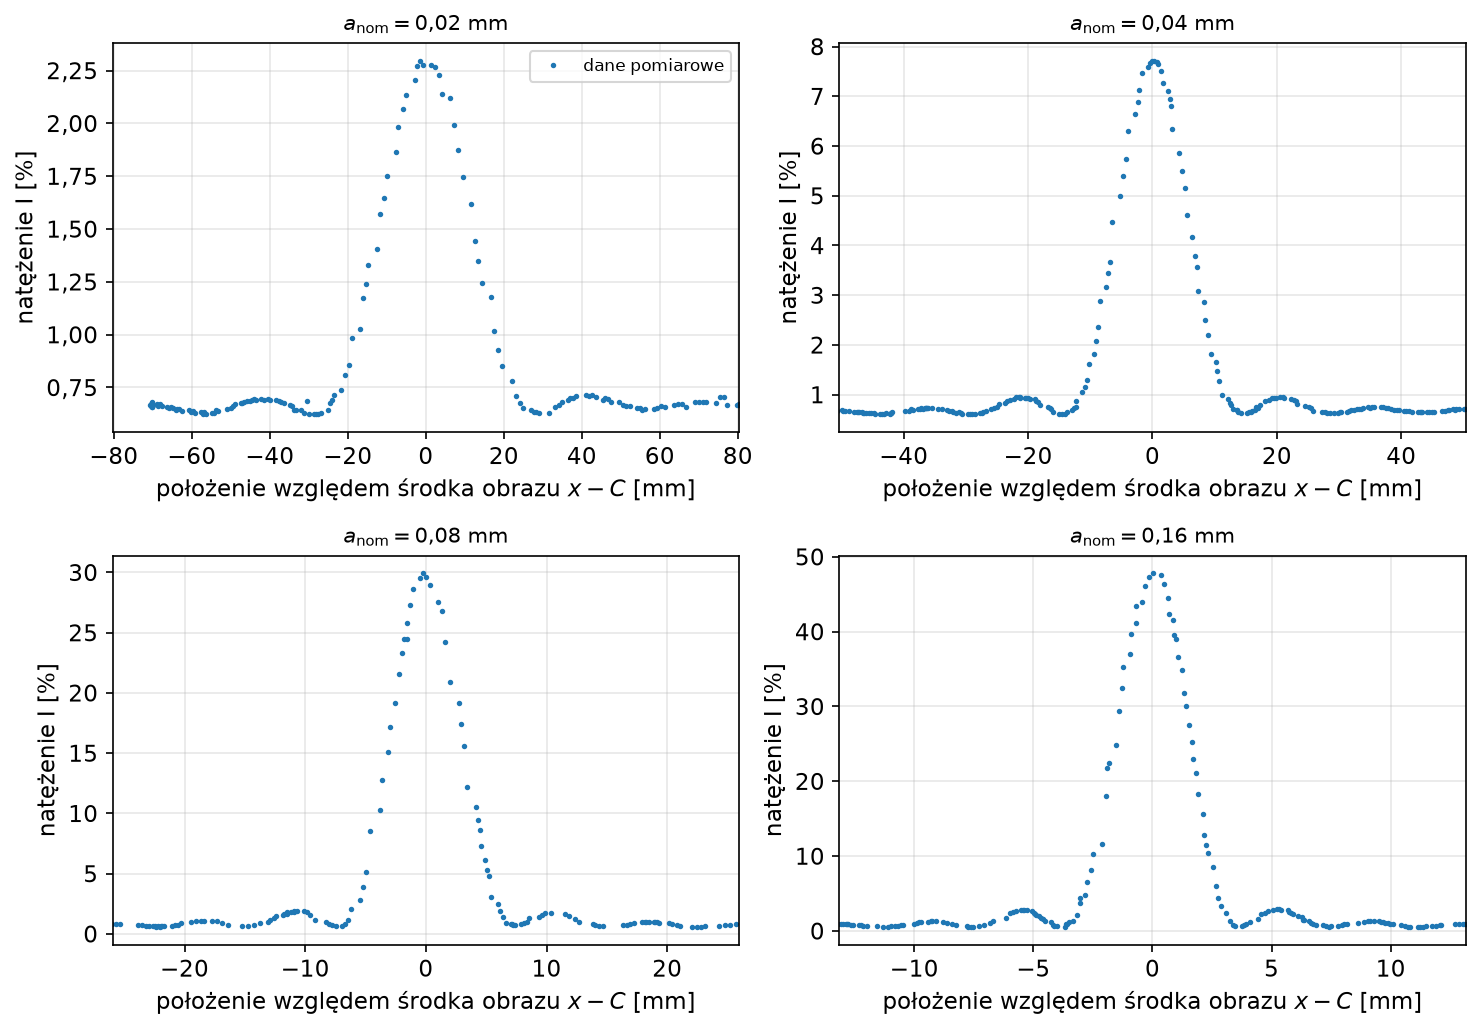

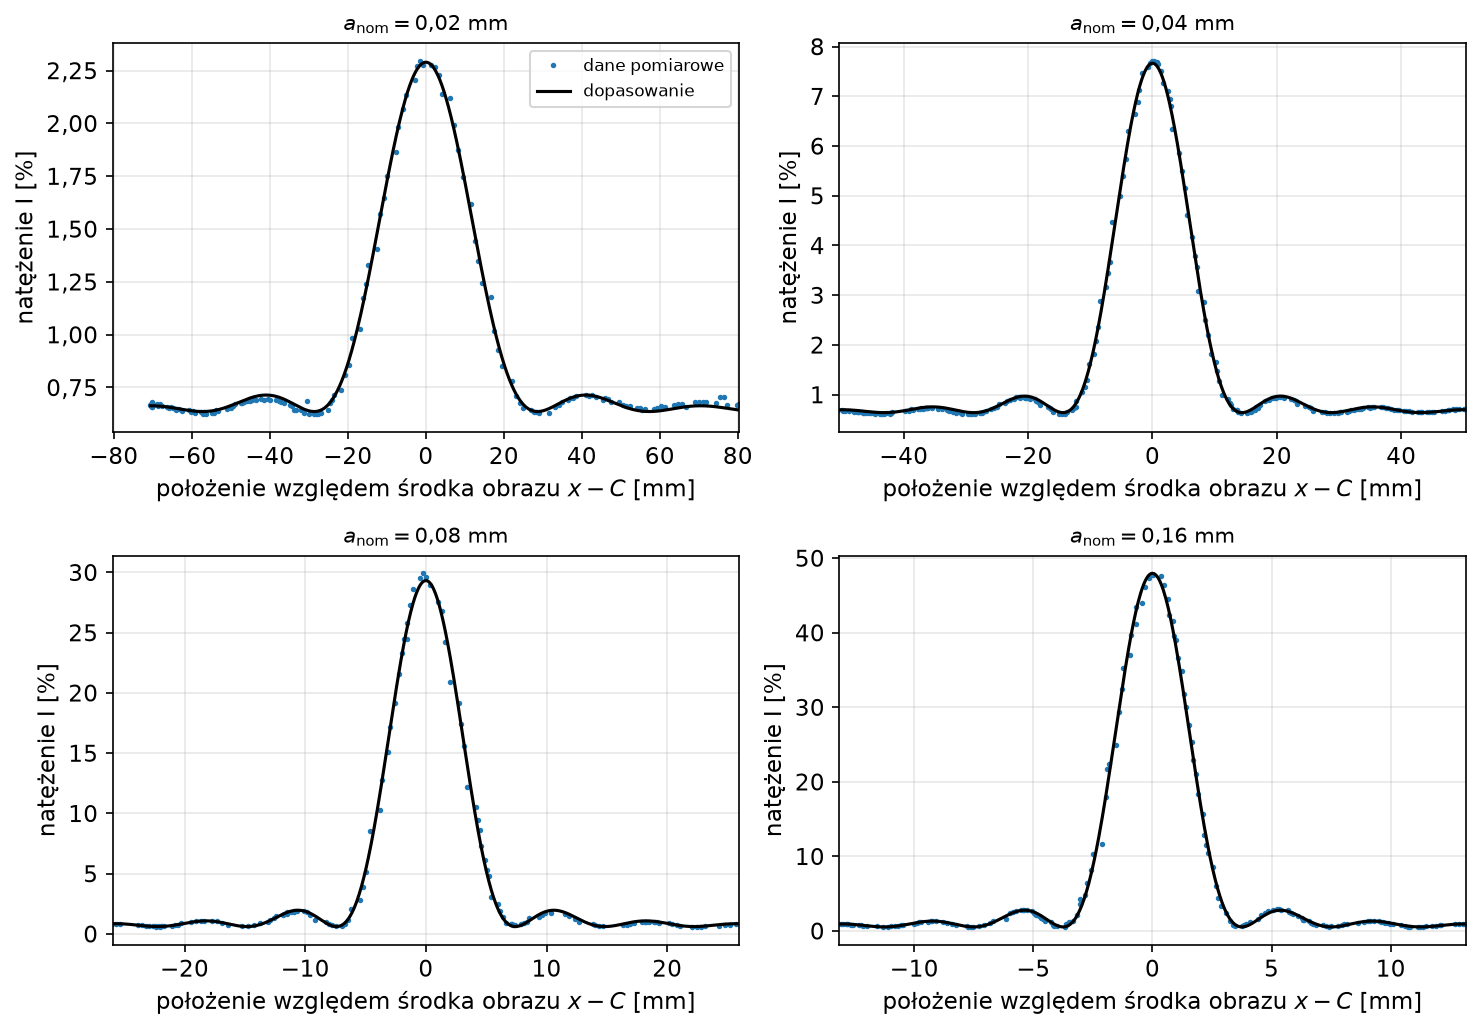

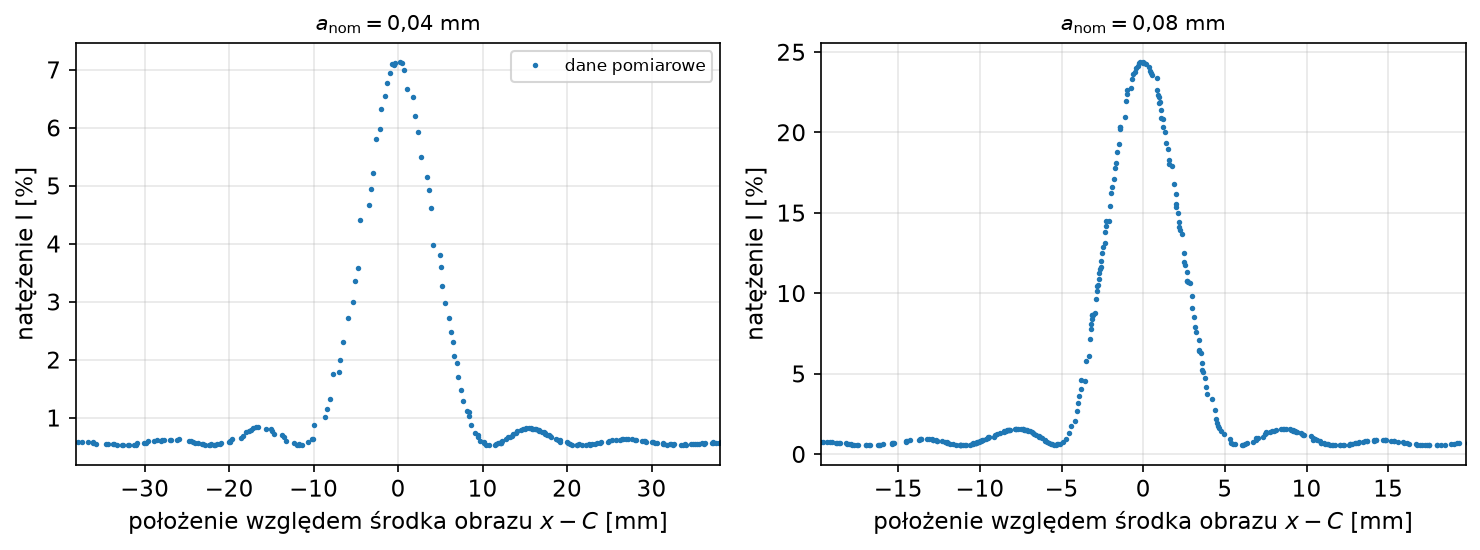

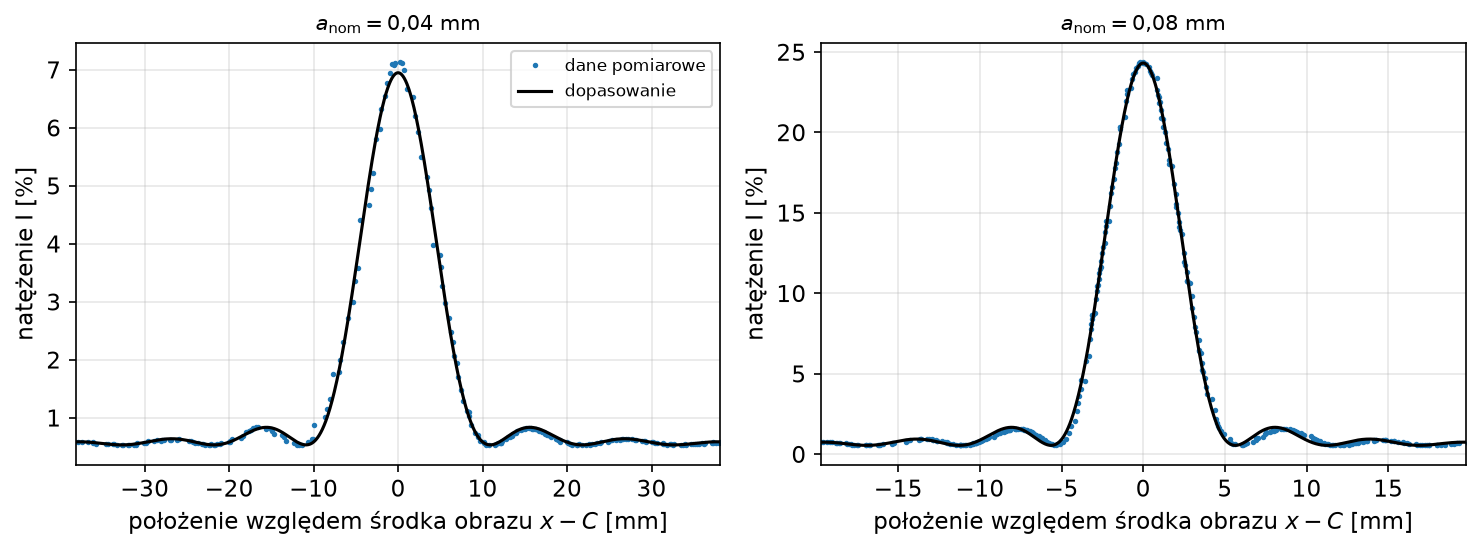

In [9]:
def siatka(n):
    kol = 2 if n > 1 else 1
    wier = int(np.ceil(n / kol))
    return plt.subplots(wier, kol, figsize=(10 if kol == 2 else 7, 3.2 * wier + 0.6), squeeze=False)

def wykres_przejazdow(pozycje, plik_pdf, z_fitem, zakres=3.5, opis_x='położenie względem środka obrazu $x - C$ [mm]'):
    '''pozycje: lista (tytuł, df, fit); oś x do ±zakres·π/B_a (szerokości obwiedni), nie dalej niż dane.'''
    fig, axs = siatka(len(pozycje))
    for ax, (tytul, df, fit) in zip(axs.flat, pozycje):
        y = df['x'] - fit['C']
        ax.plot(y, df['I'], 'o', ms=1.6, color='tab:blue', label='dane pomiarowe')
        if z_fitem:
            yy = np.linspace(y.min(), y.max(), 3000)
            ax.plot(yy, fit['f'](yy + fit['C'], *fit['p']), '-', lw=1.5, color='k', label='dopasowanie')
        w = min(np.abs(y).max(), zakres * np.pi / fit['Ba'])
        ax.set_xlim(-w, w)
        ax.set_title(tytul, fontsize=10)
        ax.set_xlabel(opis_x)
        ax.set_ylabel('natężenie I [%]')
    for ax in list(axs.flat)[len(pozycje):]:
        ax.remove()
    axs.flat[0].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(plik_pdf)
    plt.show()

for L, lista in SZCZELINY.items():
    poz = [(f'$a_\\mathrm{{nom}} = {plm(a)}$ mm', wczytaj(L, plik_1(a, 1)), A_fit[L, a, 1]) for a in lista]
    wykres_przejazdow(poz, f'single_slit_{L}_raw.pdf', False)
    wykres_przejazdow(poz, f'single_slit_{L}.pdf', True)

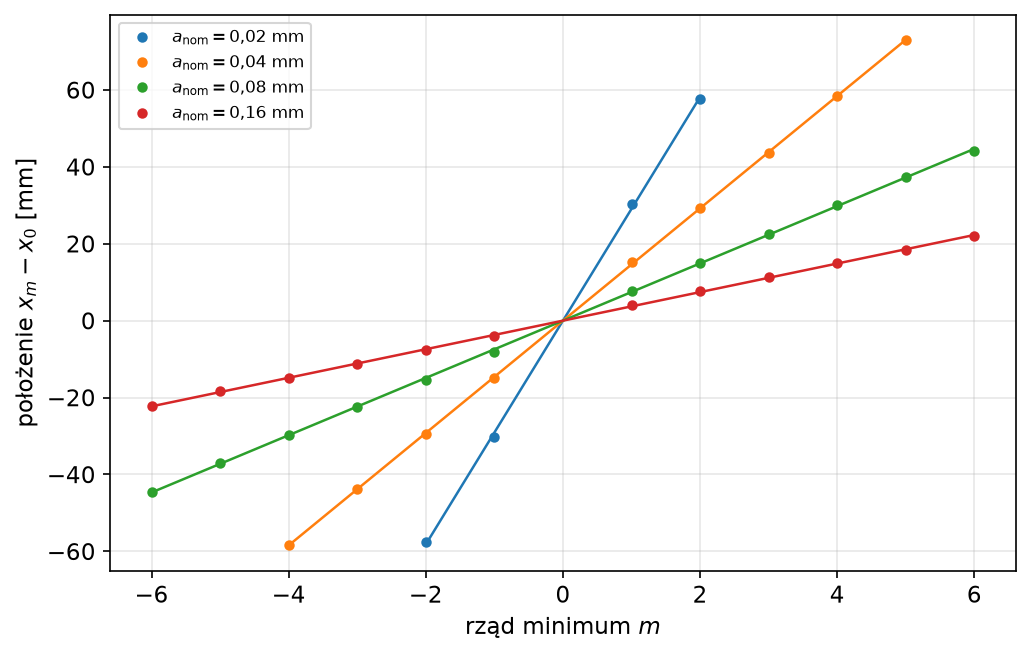

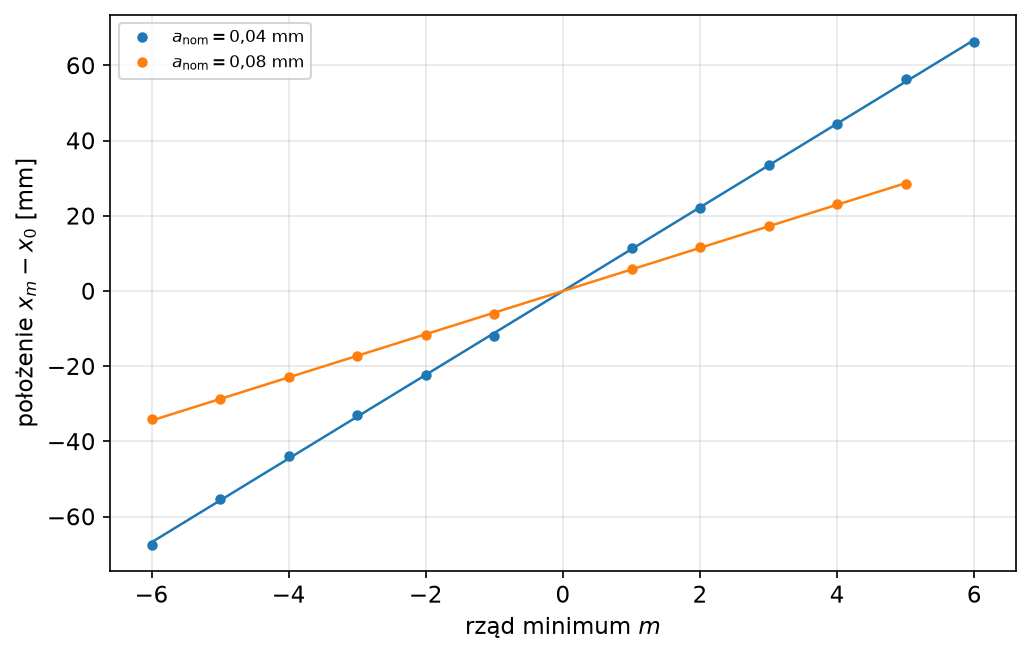

In [10]:
def wykres_regresji(serie, plik_pdf, ylabel='położenie $x_m$ [mm]', xlabel='rząd minimum $m$'):
    '''serie: lista (etykieta, regresja) — punkty i proste, przesunięte o x0 każdej serii.'''
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for i, (et, reg) in enumerate(serie):
        c = f'C{i}'
        ax.plot(reg['m'], reg['xm'] - reg['x0'], 'o', ms=4, color=c, label=et)
        mm = np.array([reg['m'].min(), reg['m'].max()])
        ax.plot(mm, reg['r'].slope * mm, '-', lw=1.2, color=c)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel.replace('$x_m$', '$x_m - x_0$'))
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(plik_pdf)
    plt.show()

for L, lista in SZCZELINY.items():
    wykres_regresji([(f'$a_\\mathrm{{nom}} = {plm(a)}$ mm', A_reg[L, a, 1]) for a in lista],
                    f'single_slit_minima_{L}.pdf')

## Część B — dwie szczeliny

Czerwony: $a \in \{0{,}04;\ 0{,}08\}$ mm × $d \in \{0{,}25;\ 0{,}50\}$ mm, zielony: $a = 0{,}08$ mm, $d \in \{0{,}25;\ 0{,}50\}$ mm.
Dopasowanie daje jednocześnie $a$ i $d$; regresja — $d$ z maksimów interferencyjnych (rząd $m'$) i $a$ z minimów
obwiedni (rząd $m$).

In [11]:
PODWOJNE = {'red': [(0.04, 0.25), (0.04, 0.5), (0.08, 0.25), (0.08, 0.5)], 'green': [(0.08, 0.25), (0.08, 0.5)]}

def plik_2(a, d, k):
    return f'double_slit_a{round(a * 100):02d}_d{round(d * 100):02d}_{k}.csv'

def analiza_N(L, uklad, pliki, N, a_nom, d_nom, z_obwiednia=True):
    '''Dopasowanie i regresje dla przejazdów jednego układu N szczelin.'''
    lam, u_lam = LAMBDA[L]
    zb = {k: [] for k in ('af', 'uaf', 'df', 'udf', 'ar', 'uar', 'dr', 'udr')}
    fity, regi = [], []
    for k, plik in enumerate(pliki, start=1):
        df = wczytaj(L, plik)
        D, u_D = df.attrs['D'], df.attrs['u_D']
        fit = dopasuj(df, N)
        rd = regresja(maksima_interferencyjne(df, fit))
        ob = minima_obwiedni(df, fit) if z_obwiednia else []
        ra = regresja(ob) if len(ob) >= 2 else None
        fity.append(fit); regi.append((rd, ra))
        c = lam * D / np.pi
        zb['af'].append(fit['Ba'] * c); zb['uaf'].append(fit['u_Ba'] * c)
        zb['df'].append(fit['Bd'] * c); zb['udf'].append(fit['u_Bd'] * c)
        zb['dr'].append(lam * D / rd['s']); zb['udr'].append(lam * D * rd['u_s'] / rd['s'] ** 2)
        if ra:
            zb['ar'].append(lam * D / ra['s']); zb['uar'].append(lam * D * ra['u_s'] / ra['s'] ** 2)
        print(f"{NAZWA[L]:8s} {uklad}, przejazd {k}: B_a = {fit['Ba']:.4f} ± {fit['u_Ba']:.4f}, "
              f"B_d = {fit['Bd']:.4f} ± {fit['u_Bd']:.4f} mm⁻¹, RMS = {fit['rms']:.2f} %  |  "
              f"maksima: {rd['n']}, s_d = {rd['s']:.4f} ± {rd['u_s']:.4f} mm"
              + (f"  |  minima obwiedni: {ra['n']}, s_a = {ra['s']:.3f} ± {ra['u_s']:.3f} mm" if ra else '  |  minima obwiedni: < 2'))
    w = {}
    w['a', 'dopasowanie'] = z_przejazdow(zb['af'], zb['uaf'], lam, u_lam, D, u_D)
    w['d', 'dopasowanie'] = z_przejazdow(zb['df'], zb['udf'], lam, u_lam, D, u_D)
    w['d', 'regresja'] = z_przejazdow(zb['dr'], zb['udr'], lam, u_lam, D, u_D)
    if len(zb['ar']):
        w['a', 'regresja'] = z_przejazdow(zb['ar'], zb['uar'], lam, u_lam, D, u_D)
    for (q, met), wq in w.items():
        zapisz_wynik(L, uklad, q, met, wq, a_nom if q == 'a' else d_nom)
        print(f'   → {q} ({met:11s}) = {fmt(wq)}' + (f'  (z {wq["n"]} przejazdów)' if wq['n'] < 3 else ''))
    print()
    return fity, regi

B_fit, B_reg = {}, {}
for L, lista in PODWOJNE.items():
    for a_nom, d_nom in lista:
        f, r = analiza_N(L, f'2 szczeliny, a = {a_nom}, d = {d_nom}', [plik_2(a_nom, d_nom, k) for k in (1, 2, 3)],
                         2, a_nom, d_nom)
        B_fit[L, a_nom, d_nom], B_reg[L, a_nom, d_nom] = f, r

czerwony 2 szczeliny, a = 0.04, d = 0.25, przejazd 1: B_a = 0.2167 ± 0.0007, B_d = 1.3192 ± 0.0006 mm⁻¹, RMS = 0.65 %  |  maksima: 9, s_d = 2.3479 ± 0.0091 mm  |  minima obwiedni: 8, s_a = 14.919 ± 0.162 mm
czerwony 2 szczeliny, a = 0.04, d = 0.25, przejazd 2: B_a = 0.2284 ± 0.0027, B_d = 1.3252 ± 0.0024 mm⁻¹, RMS = 1.21 %  |  maksima: 6, s_d = 2.2911 ± 0.0385 mm  |  minima obwiedni: 6, s_a = 14.961 ± 0.298 mm
czerwony 2 szczeliny, a = 0.04, d = 0.25, przejazd 3: B_a = 0.2139 ± 0.0011, B_d = 1.3086 ± 0.0009 mm⁻¹, RMS = 0.79 %  |  maksima: 9, s_d = 2.3782 ± 0.0042 mm  |  minima obwiedni: 8, s_a = 15.270 ± 0.140 mm
   → a (dopasowanie) = (0.0409 ± 0.0014) mm   [u_A = 0.0011, u_fit(śr.) = 0.0003, u_sys = 0.0008]
   → d (dopasowanie) = (0.2454 ± 0.0049) mm   [u_A = 0.0012, u_fit(śr.) = 0.0003, u_sys = 0.0048]
   → d (regresja   ) = (0.2502 ± 0.0061) mm   [u_A = 0.0036, u_fit(śr.) = 0.0026, u_sys = 0.0049]
   → a (regresja   ) = (0.0389 ± 0.0008) mm   [u_A = 0.0004, u_fit(śr.) = 0.0006, u_s

czerwony 2 szczeliny, a = 0.04, d = 0.5, przejazd 1: B_a = 0.2182 ± 0.0012, B_d = 2.6418 ± 0.0011 mm⁻¹, RMS = 2.12 %  |  maksima: 16, s_d = 1.1839 ± 0.0032 mm  |  minima obwiedni: 6, s_a = 15.946 ± 0.239 mm
czerwony 2 szczeliny, a = 0.04, d = 0.5, przejazd 2: B_a = 0.2374 ± 0.0021, B_d = 2.7386 ± 0.0017 mm⁻¹, RMS = 2.85 %  |  maksima: 15, s_d = 1.1587 ± 0.0057 mm  |  minima obwiedni: 3, s_a = 15.596 ± 0.196 mm


czerwony 2 szczeliny, a = 0.04, d = 0.5, przejazd 3: B_a = 0.2246 ± 0.0011, B_d = 2.7318 ± 0.0010 mm⁻¹, RMS = 1.73 %  |  maksima: 16, s_d = 1.1504 ± 0.0051 mm  |  minima obwiedni: 5, s_a = 15.655 ± 0.344 mm
   → a (dopasowanie) = (0.0422 ± 0.0016) mm   [u_A = 0.0014, u_fit(śr.) = 0.0003, u_sys = 0.0008]
   → d (dopasowanie) = (0.5035 ± 0.0125) mm   [u_A = 0.0077, u_fit(śr.) = 0.0002, u_sys = 0.0098]
   → d (regresja   ) = (0.5025 ± 0.0114) mm   [u_A = 0.0057, u_fit(śr.) = 0.0021, u_sys = 0.0098]
   → a (regresja   ) = (0.0372 ± 0.0008) mm   [u_A = 0.0003, u_fit(śr.) = 0.0006, u_sys = 0.0007]



czerwony 2 szczeliny, a = 0.08, d = 0.25, przejazd 1: B_a = 0.4429 ± 0.0016, B_d = 1.3668 ± 0.0014 mm⁻¹, RMS = 1.01 %  |  maksima: 5, s_d = 2.1881 ± 0.0176 mm  |  minima obwiedni: 8, s_a = 7.463 ± 0.073 mm
czerwony 2 szczeliny, a = 0.08, d = 0.25, przejazd 2: B_a = 0.4326 ± 0.0022, B_d = 1.2793 ± 0.0016 mm⁻¹, RMS = 1.23 %  |  maksima: 5, s_d = 2.3176 ± 0.0171 mm  |  minima obwiedni: 8, s_a = 7.648 ± 0.059 mm
czerwony 2 szczeliny, a = 0.08, d = 0.25, przejazd 3: B_a = 0.4082 ± 0.0055, B_d = 1.2300 ± 0.0049 mm⁻¹, RMS = 1.84 %  |  maksima: 5, s_d = 2.3204 ± 0.0677 mm  |  minima obwiedni: 8, s_a = 7.480 ± 0.145 mm
   → a (dopasowanie) = (0.0797 ± 0.0030) mm   [u_A = 0.0025, u_fit(śr.) = 0.0007, u_sys = 0.0016]
   → d (dopasowanie) = (0.2406 ± 0.0109) mm   [u_A = 0.0098, u_fit(śr.) = 0.0006, u_sys = 0.0047]
   → d (regresja   ) = (0.2573 ± 0.0083) mm   [u_A = 0.0066, u_fit(śr.) = 0.0046, u_sys = 0.0050]
   → a (regresja   ) = (0.0777 ± 0.0017) mm   [u_A = 0.0008, u_fit(śr.) = 0.0010, u_sys 

czerwony 2 szczeliny, a = 0.08, d = 0.5, przejazd 1: B_a = 0.4320 ± 0.0016, B_d = 2.7291 ± 0.0016 mm⁻¹, RMS = 1.36 %  |  maksima: 9, s_d = 1.1493 ± 0.0069 mm  |  minima obwiedni: 8, s_a = 7.552 ± 0.112 mm
czerwony 2 szczeliny, a = 0.08, d = 0.5, przejazd 2: B_a = 0.4127 ± 0.0040, B_d = 2.5872 ± 0.0031 mm⁻¹, RMS = 2.87 %  |  maksima: 9, s_d = 1.2185 ± 0.0102 mm  |  minima obwiedni: 8, s_a = 7.772 ± 0.155 mm


czerwony 2 szczeliny, a = 0.08, d = 0.5, przejazd 3: B_a = 0.4265 ± 0.0055, B_d = 2.7261 ± 0.0049 mm⁻¹, RMS = 4.15 %  |  maksima: 9, s_d = 1.1487 ± 0.0124 mm  |  minima obwiedni: 8, s_a = 7.655 ± 0.127 mm
   → a (dopasowanie) = (0.0789 ± 0.0021) mm   [u_A = 0.0014, u_fit(śr.) = 0.0008, u_sys = 0.0015]
   → d (dopasowanie) = (0.4992 ± 0.0151) mm   [u_A = 0.0115, u_fit(śr.) = 0.0006, u_sys = 0.0098]
   → d (regresja   ) = (0.4995 ± 0.0161) mm   [u_A = 0.0128, u_fit(śr.) = 0.0043, u_sys = 0.0098]
   → a (regresja   ) = (0.0764 ± 0.0017) mm   [u_A = 0.0008, u_fit(śr.) = 0.0013, u_sys = 0.0015]

zielony  2 szczeliny, a = 0.08, d = 0.25, przejazd 1: B_a = 0.5404 ± 0.0013, B_d = 1.7394 ± 0.0011 mm⁻¹, RMS = 0.96 %  |  maksima: 5, s_d = 1.7313 ± 0.0070 mm  |  minima obwiedni: 8, s_a = 5.892 ± 0.115 mm


zielony  2 szczeliny, a = 0.08, d = 0.25, przejazd 2: B_a = 0.5418 ± 0.0019, B_d = 1.7205 ± 0.0016 mm⁻¹, RMS = 1.64 %  |  maksima: 5, s_d = 1.7062 ± 0.0327 mm  |  minima obwiedni: 8, s_a = 5.945 ± 0.117 mm
zielony  2 szczeliny, a = 0.08, d = 0.25, przejazd 3: B_a = 0.5641 ± 0.0023, B_d = 1.7407 ± 0.0019 mm⁻¹, RMS = 1.23 %  |  maksima: 5, s_d = 1.7335 ± 0.0074 mm  |  minima obwiedni: 8, s_a = 5.832 ± 0.064 mm
   → a (dopasowanie) = (0.0810 ± 0.0022) mm   [u_A = 0.0015, u_fit(śr.) = 0.0003, u_sys = 0.0017]
   → d (dopasowanie) = (0.2558 ± 0.0054) mm   [u_A = 0.0013, u_fit(śr.) = 0.0002, u_sys = 0.0052]
   → d (regresja   ) = (0.2689 ± 0.0058) mm   [u_A = 0.0018, u_fit(śr.) = 0.0031, u_sys = 0.0055]
   → a (regresja   ) = (0.0787 ± 0.0017) mm   [u_A = 0.0006, u_fit(śr.) = 0.0013, u_sys = 0.0016]



zielony  2 szczeliny, a = 0.08, d = 0.5, przejazd 1: B_a = 0.5837 ± 0.0023, B_d = 3.4805 ± 0.0018 mm⁻¹, RMS = 1.62 %  |  maksima: 9, s_d = 0.8923 ± 0.0029 mm  |  minima obwiedni: 8, s_a = 5.747 ± 0.052 mm
zielony  2 szczeliny, a = 0.08, d = 0.5, przejazd 2: B_a = 0.5716 ± 0.0040, B_d = 3.4625 ± 0.0027 mm⁻¹, RMS = 2.42 %  |  maksima: 8, s_d = 0.8920 ± 0.0059 mm  |  minima obwiedni: 8, s_a = 5.703 ± 0.072 mm


zielony  2 szczeliny, a = 0.08, d = 0.5, przejazd 3: B_a = 0.5591 ± 0.0047, B_d = 3.3167 ± 0.0036 mm⁻¹, RMS = 3.54 %  |  maksima: 9, s_d = 0.9469 ± 0.0051 mm  |  minima obwiedni: 8, s_a = 5.866 ± 0.071 mm
   → a (dopasowanie) = (0.0843 ± 0.0022) mm   [u_A = 0.0014, u_fit(śr.) = 0.0006, u_sys = 0.0017]
   → d (dopasowanie) = (0.5046 ± 0.0144) mm   [u_A = 0.0101, u_fit(śr.) = 0.0004, u_sys = 0.0103]
   → d (regresja   ) = (0.5095 ± 0.0168) mm   [u_A = 0.0132, u_fit(śr.) = 0.0027, u_sys = 0.0104]
   → a (regresja   ) = (0.0803 ± 0.0019) mm   [u_A = 0.0009, u_fit(śr.) = 0.0009, u_sys = 0.0016]



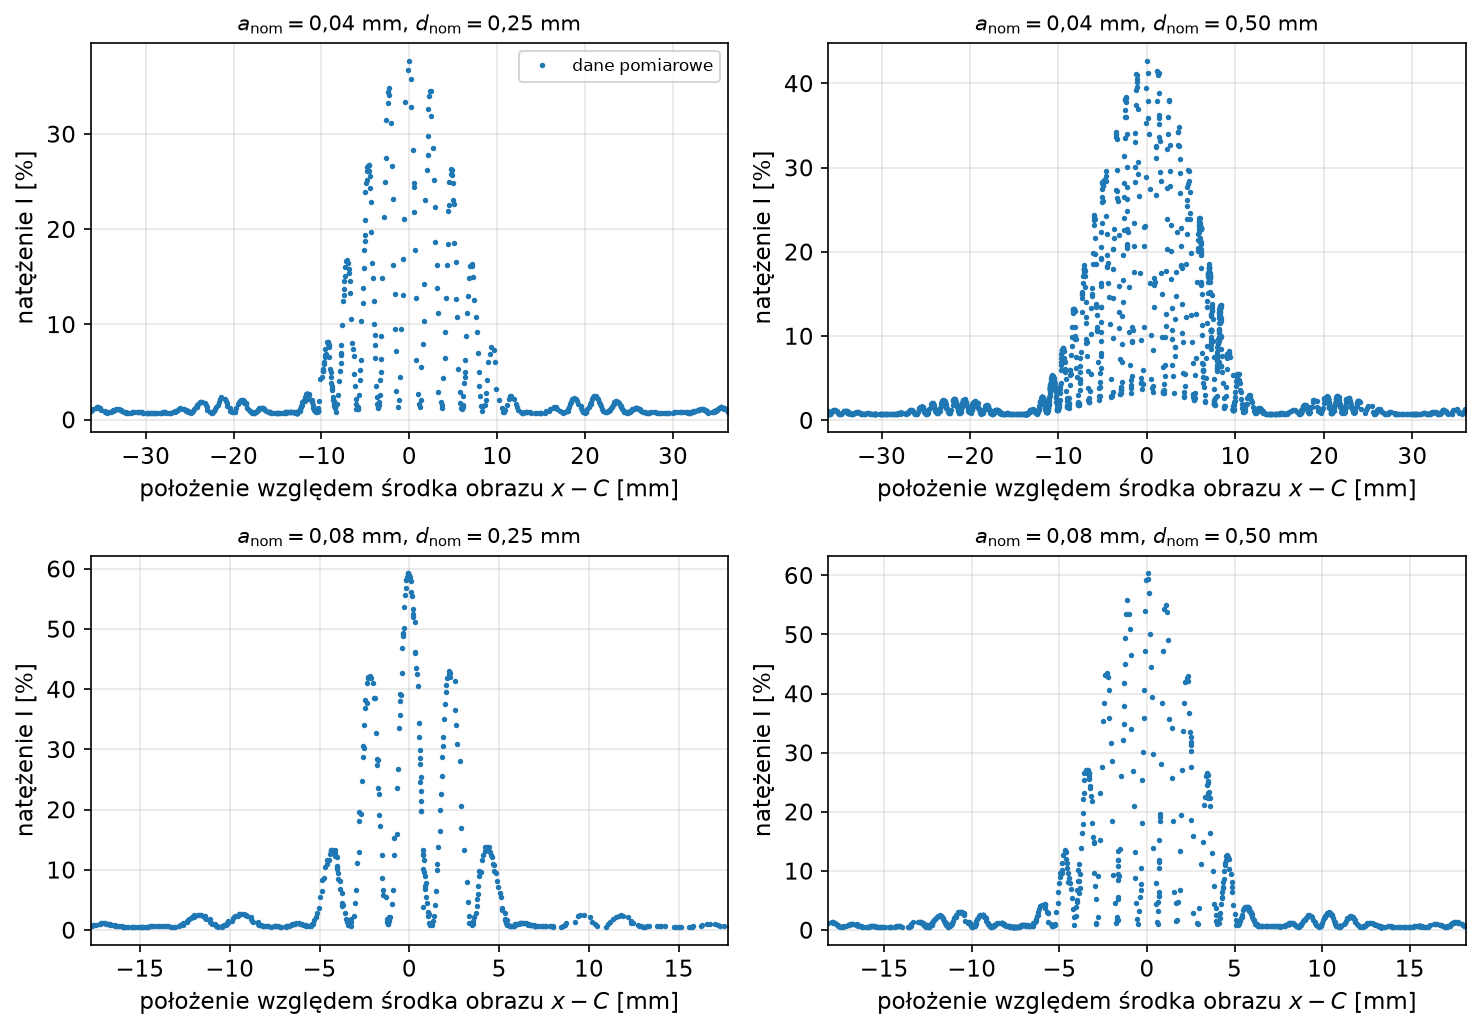

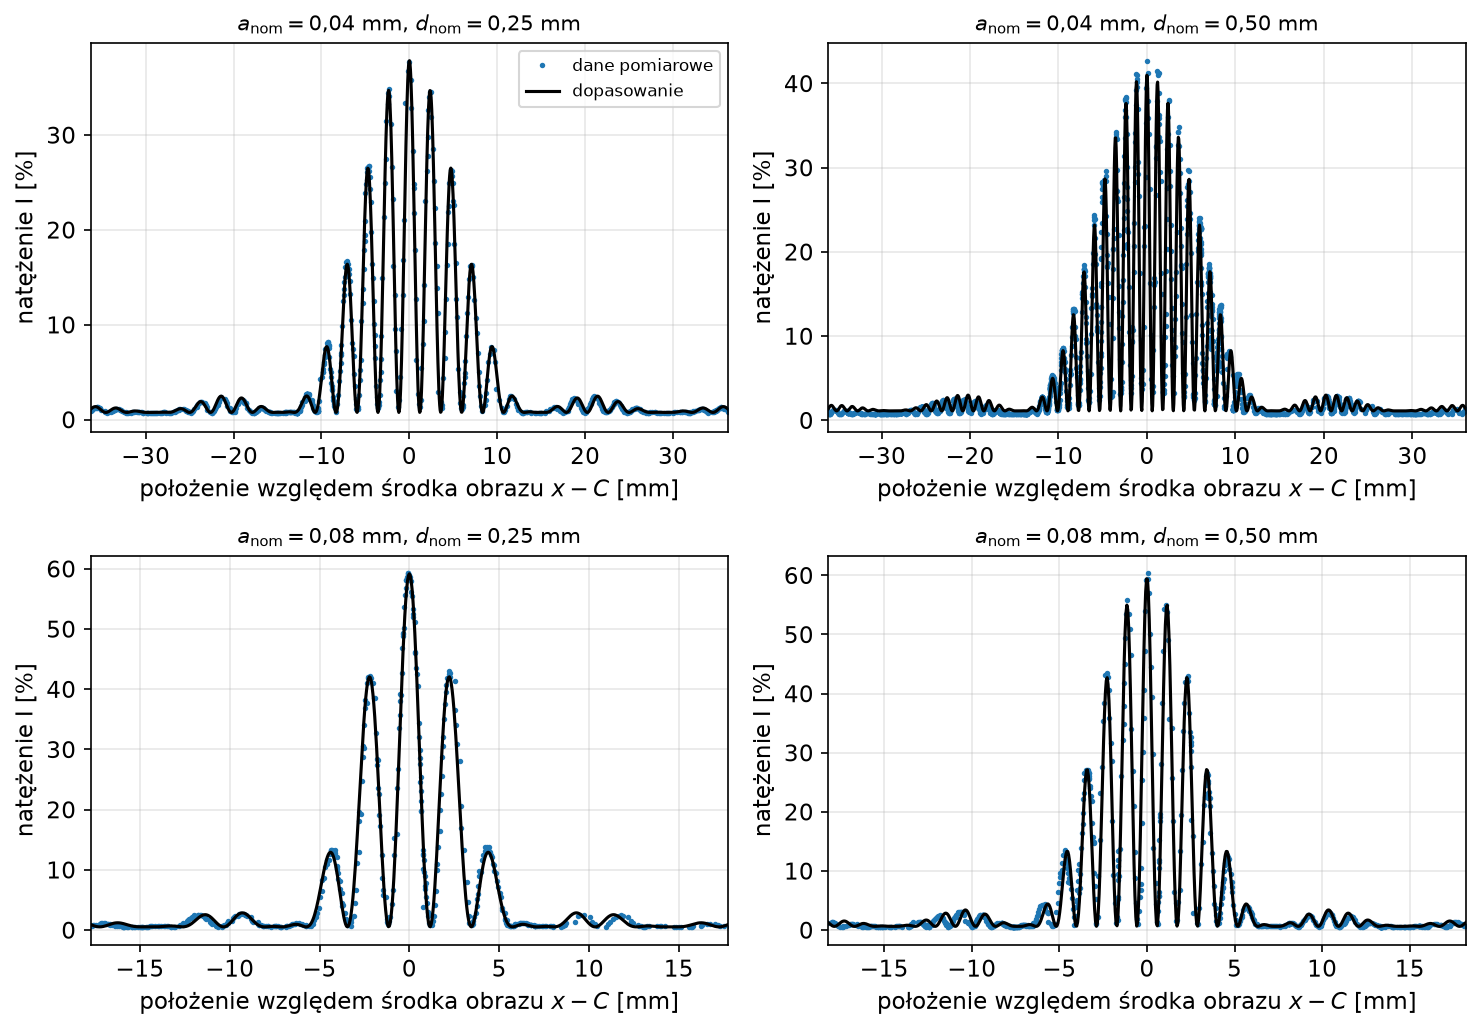

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


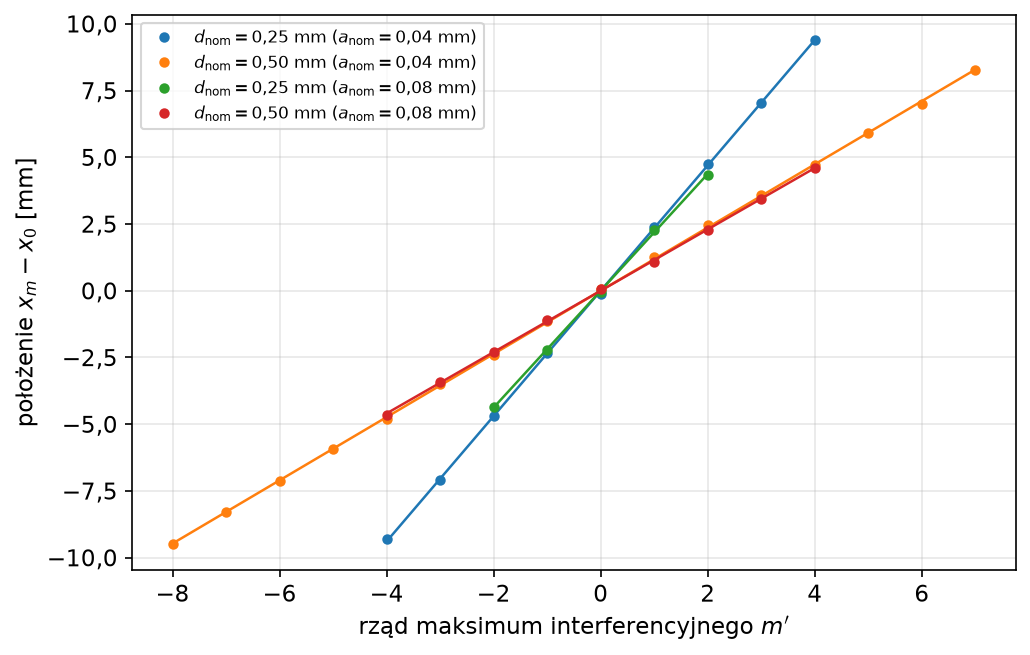

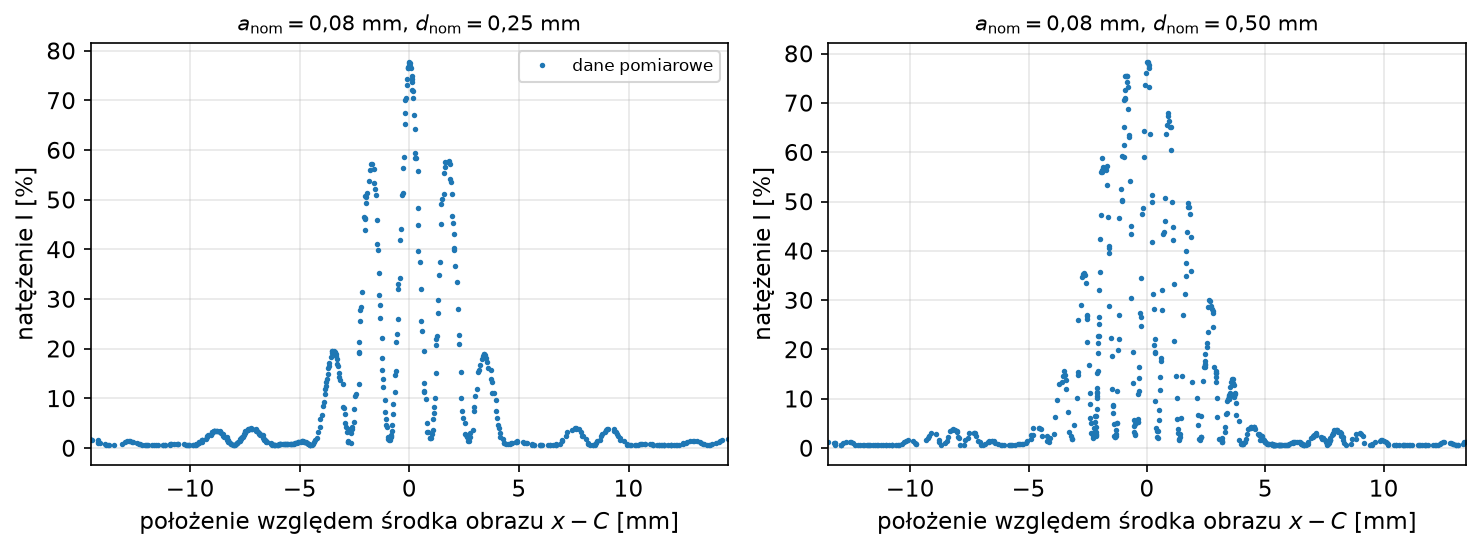

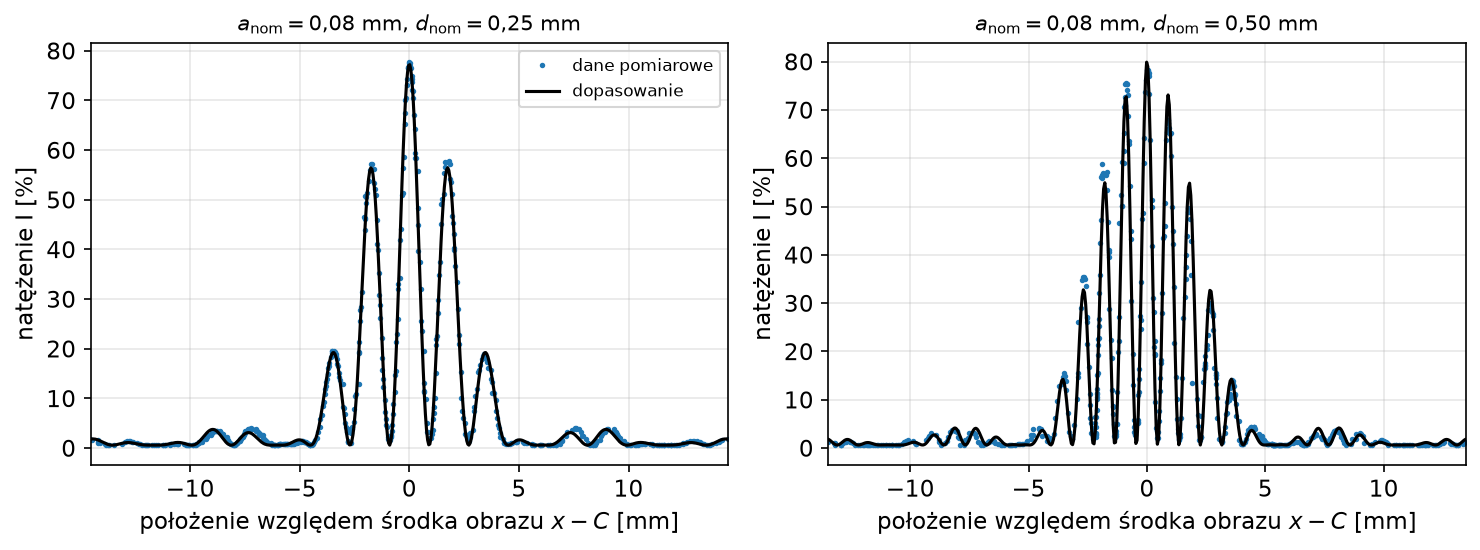

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


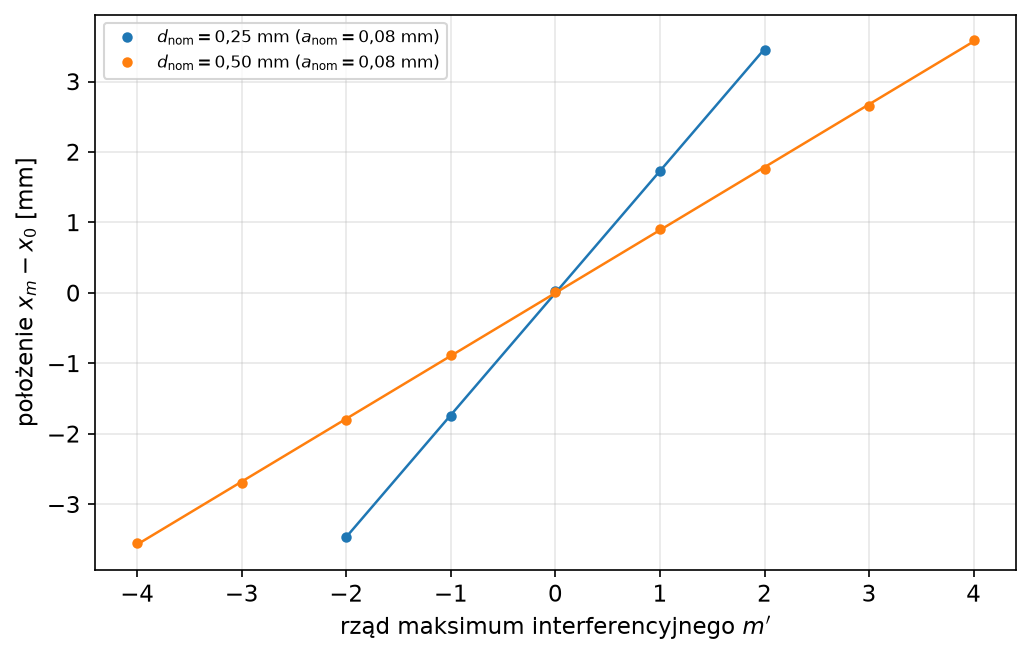

In [12]:
for L, lista in PODWOJNE.items():
    poz = [(f'$a_\\mathrm{{nom}} = {plm(a)}$ mm, $d_\\mathrm{{nom}} = {plm(d)}$ mm',
            wczytaj(L, plik_2(a, d, 1)), B_fit[L, a, d][0]) for a, d in lista]
    wykres_przejazdow(poz, f'double_slit_{L}_raw.pdf', False, zakres=2.5)
    wykres_przejazdow(poz, f'double_slit_{L}.pdf', True, zakres=2.5)
    wykres_regresji([(f'$d_\\mathrm{{nom}} = {plm(d)}$ mm ($a_\\mathrm{{nom}} = {plm(a)}$ mm)',
                      B_reg[L, a, d][0][0]) for a, d in lista], f'double_slit_maxima_{L}.pdf',
                    xlabel="rząd maksimum interferencyjnego $m'$")

## Część C — układy $N$ szczelin

$a = 0{,}04$ mm, $d = 0{,}125$ mm. Czerwony: $N = 2, 3, 4, 5$, zielony: $N = 4$. Część jakościowa (szerokość
i natężenie maksimów głównych, liczba maksimów pobocznych), a dodatkowo $a$ i $d$ z dopasowania i $d$
z regresji położeń maksimów głównych. Minima obwiedni leżą przy $|x - C| \approx \lambda D/a$, tam gdzie
maksima główne są już bardzo słabe — regresji dla $a$ nie wykonano.

In [13]:
WIELE = {'red': [2, 3, 4, 5], 'green': [4]}
C_fit, C_reg = {}, {}
for L, lista in WIELE.items():
    for N in lista:
        f, r = analiza_N(L, f'N = {N} szczelin, a = 0.04, d = 0.125',
                         [f'multi_slit_N{N}_{k}.csv' for k in (1, 2, 3)], N, 0.04, 0.125, z_obwiednia=False)
        C_fit[L, N], C_reg[L, N] = f, r

czerwony N = 2 szczelin, a = 0.04, d = 0.125, przejazd 1: B_a = 0.2120 ± 0.0026, B_d = 0.7030 ± 0.0021 mm⁻¹, RMS = 0.29 %  |  maksima: 5, s_d = 4.2297 ± 0.0260 mm  |  minima obwiedni: < 2
czerwony N = 2 szczelin, a = 0.04, d = 0.125, przejazd 2: B_a = 0.2354 ± 0.0018, B_d = 0.7059 ± 0.0015 mm⁻¹, RMS = 0.24 %  |  maksima: 5, s_d = 4.2905 ± 0.0711 mm  |  minima obwiedni: < 2
czerwony N = 2 szczelin, a = 0.04, d = 0.125, przejazd 3: B_a = 0.2259 ± 0.0016, B_d = 0.6824 ± 0.0013 mm⁻¹, RMS = 0.25 %  |  maksima: 5, s_d = 4.4547 ± 0.0388 mm  |  minima obwiedni: < 2
   → a (dopasowanie) = (0.0418 ± 0.0019) mm   [u_A = 0.0017, u_fit(śr.) = 0.0004, u_sys = 0.0008]
   → d (dopasowanie) = (0.1298 ± 0.0031) mm   [u_A = 0.0018, u_fit(śr.) = 0.0003, u_sys = 0.0025]
   → d (regresja   ) = (0.1353 ± 0.0038) mm   [u_A = 0.0027, u_fit(śr.) = 0.0015, u_sys = 0.0026]



czerwony N = 3 szczelin, a = 0.04, d = 0.125, przejazd 1: B_a = 0.2435 ± 0.0019, B_d = 0.6824 ± 0.0010 mm⁻¹, RMS = 0.63 %  |  maksima: 5, s_d = 4.4688 ± 0.0493 mm  |  minima obwiedni: < 2
czerwony N = 3 szczelin, a = 0.04, d = 0.125, przejazd 2: B_a = 0.2163 ± 0.0016, B_d = 0.6928 ± 0.0009 mm⁻¹, RMS = 0.79 %  |  maksima: 5, s_d = 4.4943 ± 0.0544 mm  |  minima obwiedni: < 2


czerwony N = 3 szczelin, a = 0.04, d = 0.125, przejazd 3: B_a = 0.2465 ± 0.0012, B_d = 0.6997 ± 0.0005 mm⁻¹, RMS = 0.61 %  |  maksima: 5, s_d = 4.4523 ± 0.0109 mm  |  minima obwiedni: < 2
   → a (dopasowanie) = (0.0438 ± 0.0025) mm   [u_A = 0.0024, u_fit(śr.) = 0.0003, u_sys = 0.0009]
   → d (dopasowanie) = (0.1288 ± 0.0028) mm   [u_A = 0.0012, u_fit(śr.) = 0.0002, u_sys = 0.0025]
   → d (regresja   ) = (0.1308 ± 0.0026) mm   [u_A = 0.0005, u_fit(śr.) = 0.0012, u_sys = 0.0026]

czerwony N = 4 szczelin, a = 0.04, d = 0.125, przejazd 1: B_a = 0.2482 ± 0.0016, B_d = 0.6825 ± 0.0006 mm⁻¹, RMS = 1.25 %  |  maksima: 5, s_d = 4.4982 ± 0.0443 mm  |  minima obwiedni: < 2


czerwony N = 4 szczelin, a = 0.04, d = 0.125, przejazd 2: B_a = 0.2443 ± 0.0008, B_d = 0.6839 ± 0.0004 mm⁻¹, RMS = 0.82 %  |  maksima: 5, s_d = 4.5388 ± 0.0265 mm  |  minima obwiedni: < 2
czerwony N = 4 szczelin, a = 0.04, d = 0.125, przejazd 3: B_a = 0.2214 ± 0.0010, B_d = 0.6894 ± 0.0004 mm⁻¹, RMS = 0.91 %  |  maksima: 5, s_d = 4.5633 ± 0.0236 mm  |  minima obwiedni: < 2
   → a (dopasowanie) = (0.0443 ± 0.0022) mm   [u_A = 0.0021, u_fit(śr.) = 0.0002, u_sys = 0.0009]
   → d (dopasowanie) = (0.1276 ± 0.0025) mm   [u_A = 0.0005, u_fit(śr.) = 0.0001, u_sys = 0.0025]
   → d (regresja   ) = (0.1290 ± 0.0026) mm   [u_A = 0.0007, u_fit(śr.) = 0.0009, u_sys = 0.0025]



czerwony N = 5 szczelin, a = 0.04, d = 0.125, przejazd 1: B_a = 0.2907 ± 0.0019, B_d = 0.6920 ± 0.0006 mm⁻¹, RMS = 2.23 %  |  maksima: 3, s_d = 4.4930 ± 0.0682 mm  |  minima obwiedni: < 2
czerwony N = 5 szczelin, a = 0.04, d = 0.125, przejazd 2: B_a = 0.2717 ± 0.0018, B_d = 0.6975 ± 0.0006 mm⁻¹, RMS = 1.14 %  |  maksima: 3, s_d = 4.4742 ± 0.0585 mm  |  minima obwiedni: < 2


czerwony N = 5 szczelin, a = 0.04, d = 0.125, przejazd 3: B_a = 0.2623 ± 0.0011, B_d = 0.7053 ± 0.0003 mm⁻¹, RMS = 1.10 %  |  maksima: 3, s_d = 4.4226 ± 0.0166 mm  |  minima obwiedni: < 2
   → a (dopasowanie) = (0.0512 ± 0.0023) mm   [u_A = 0.0021, u_fit(śr.) = 0.0003, u_sys = 0.0010]
   → d (dopasowanie) = (0.1300 ± 0.0027) mm   [u_A = 0.0010, u_fit(śr.) = 0.0001, u_sys = 0.0025]
   → d (regresja   ) = (0.1311 ± 0.0027) mm   [u_A = 0.0008, u_fit(śr.) = 0.0015, u_sys = 0.0026]



zielony  N = 4 szczelin, a = 0.04, d = 0.125, przejazd 1: B_a = 0.3187 ± 0.0026, B_d = 0.9642 ± 0.0011 mm⁻¹, RMS = 2.28 %  |  maksima: 5, s_d = 3.3663 ± 0.0615 mm  |  minima obwiedni: < 2


zielony  N = 4 szczelin, a = 0.04, d = 0.125, przejazd 2: B_a = 0.3070 ± 0.0022, B_d = 0.8679 ± 0.0008 mm⁻¹, RMS = 3.55 %  |  maksima: 5, s_d = 3.5657 ± 0.0466 mm  |  minima obwiedni: < 2
zielony  N = 4 szczelin, a = 0.04, d = 0.125, przejazd 3: B_a = 0.2830 ± 0.0011, B_d = 0.8596 ± 0.0004 mm⁻¹, RMS = 1.91 %  |  maksima: 5, s_d = 3.6046 ± 0.0175 mm  |  minima obwiedni: < 2
   → a (dopasowanie) = (0.0447 ± 0.0022) mm   [u_A = 0.0020, u_fit(śr.) = 0.0003, u_sys = 0.0009]
   → d (dopasowanie) = (0.1324 ± 0.0071) mm   [u_A = 0.0065, u_fit(śr.) = 0.0001, u_sys = 0.0027]
   → d (regresja   ) = (0.1321 ± 0.0046) mm   [u_A = 0.0037, u_fit(śr.) = 0.0018, u_sys = 0.0027]



### Czy skala jest wspólna dla wszystkich przejazdów?

Wszystkie przejazdy szły od ogranicznika do ogranicznika, a zapisana długość $L$ waha się o kilka procent. Jeśli to zmienna utrata impulsów, to w obrębie układu $\ln B$ powinno maleć z $\ln L$ z nachyleniem $-1$; jeśli obcięcie zapisu (start od ostatniego zawrotu) — nachylenie 0.

In [14]:
def L_zapisu(L, plik):
    return np.ptp(pd.read_csv(Path(L) / plik)['x'])

grupy = {}
for (L, a, k), f in A_fit.items():
    grupy.setdefault((L, 'A', a), []).append((L_zapisu(L, plik_1(a, k)), f['Ba']))
for (L, a, d), fity in B_fit.items():
    for k, f in enumerate(fity, start=1):
        grupy.setdefault((L, 'B', a, d), []).append((L_zapisu(L, plik_2(a, d, k)), f['Bd']))
for (L, N), fity in C_fit.items():
    for k, f in enumerate(fity, start=1):
        grupy.setdefault((L, 'C', N), []).append((L_zapisu(L, f'multi_slit_N{N}_{k}.csv'), f['Bd']))
dlnL, dlnB = [], []
for v in grupy.values():
    v = np.log(np.array(v))
    dlnL += list(v[:, 0] - v[:, 0].mean()); dlnB += list(v[:, 1] - v[:, 1].mean())
r = linregress(dlnL, dlnB)
print(f'{len(dlnL)} przejazdów, {len(grupy)} układów: d ln B / d ln L = {r.slope:.2f} ± {r.stderr:.2f}; '
      f'|nachylenie + 1|/u = {abs(r.slope + 1) / r.stderr:.1f}')
print(f'zapisane długości: {zakresy.min():.1f}–{zakresy.max():.1f} mm, mediana {zakresy.median():.1f} mm')

51 przejazdów, 17 układów: d ln B / d ln L = 0.28 ± 0.28; |nachylenie + 1|/u = 4.6
zapisane długości: 77.9–85.8 mm, mediana 83.0 mm


### Maksima główne i poboczne w funkcji $N$

Dla każdego przejazdu: szerokość połówkowa (FWHM) centralnego maksimum głównego, wysokość maksimum centralnego
i liczba maksimów pobocznych między maksimum centralnym a pierwszymi maksimami głównymi (po obu stronach;
teoretycznie $N - 2$ z każdej strony). Teoria: FWHM maksimum głównego $\propto 1/N$.
Maksima poboczne szukane w danych uśrednionych co 0,05 mm, z progiem wysokości 0,5 % maksimum.

In [15]:
from scipy.signal import find_peaks

def maksima_poboczne(df, fit):
    x, I = df['x'].to_numpy(), df['I'].to_numpy()
    sd = np.pi / fit['Bd']
    kosz = np.round((x - fit['C']) / (0.05 * SKALA_X)) * (0.05 * SKALA_X)
    g = pd.Series(I).groupby(kosz).mean()
    y, Ig = g.index.to_numpy(), g.to_numpy()
    pk, _ = find_peaks(Ig, prominence=0.005 * Ig.max())
    yp = y[pk]
    marg = 0.25 * sd / fit['N']
    lewo = np.sum((yp < -marg) & (yp > -sd + marg))
    prawo = np.sum((yp > marg) & (yp < sd - marg))
    return lewo, prawo

wiersze = []
for (L, N), fity in C_fit.items():
    for k, fit in enumerate(fity, start=1):
        df = wczytaj(L, f'multi_slit_N{N}_{k}.csv')
        y = df['x'].to_numpy() - fit['C']
        m = np.abs(y) < 0.5 * np.pi / fit['Bd']
        szer = fwhm(y[m], df['I'].to_numpy()[m])
        lw, pr = maksima_poboczne(df, fit)
        wiersze.append(dict(laser=L, N=N, k=k, FWHM=szer, I_max=df['I'].max(), pob_lewo=lw, pob_prawo=pr))
tab_N = pd.DataFrame(wiersze)
print(tab_N.to_string(index=False, float_format='%.3f'))
podsum_N = tab_N.groupby(['laser', 'N']).agg(FWHM=('FWHM', 'mean'), u_FWHM=('FWHM', lambda v: v.std(ddof=1) / np.sqrt(len(v))),
                                             I_max=('I_max', 'mean'), pob_lewo=('pob_lewo', 'median'),
                                             pob_prawo=('pob_prawo', 'median')).reset_index()
podsum_N['N·FWHM'] = podsum_N['N'] * podsum_N['FWHM']

def fwhm_teor(N, Bd):
    '''FWHM maksimum głównego czynnika [sin(N B y)/(N sin(B y))]² (numerycznie).'''
    y = np.linspace(-np.pi / Bd / 2, np.pi / Bd / 2, 200001)[1:]
    s = np.sin(Bd * y)
    f = np.where(np.abs(s) < 1e-12, 1.0, (np.sin(N * Bd * y) / (N * np.where(np.abs(s) < 1e-12, 1, s))) ** 2)
    return np.ptp(y[f >= 0.5])
podsum_N['FWHM_teor'] = [fwhm_teor(r.N, np.mean([f['Bd'] for f in C_fit[r.laser, r.N]])) for r in podsum_N.itertuples()]
podsum_N['u_FWHM'] *= t68(3)
podsum_N['z_FWHM'] = (podsum_N['FWHM'] - podsum_N['FWHM_teor']).abs() / podsum_N['u_FWHM']
podsum_N['u_I_max'] = tab_N.groupby(['laser', 'N'])['I_max'].agg(lambda v: t68(3) * v.std(ddof=1) / np.sqrt(len(v))).to_numpy()
print('\n', podsum_N.to_string(index=False, float_format='%.3f'))

# I_max ∝ N^p: regresja ważona log I_max = log c + p log N (laser czerwony), wagi z rozrzutu przejazdów
r_ = podsum_N[podsum_N['laser'] == 'red']
lnN, lnI, u_lnI = np.log(r_['N']), np.log(r_['I_max']), r_['u_I_max'] / r_['I_max']
(p_N, lnc), V_N = np.polyfit(lnN, lnI, 1, w=1 / u_lnI, cov='unscaled')
u_p_N = np.sqrt(V_N[0, 0])
chi2_N = np.sum(((lnI - (p_N * lnN + lnc)) / u_lnI) ** 2)
print(f'I_max ∝ N^p: p = {p_N:.2f} ± {u_p_N:.2f}  (χ²/ν = {chi2_N / (len(r_) - 2):.2f}); |p − 2|/u = {abs(p_N - 2) / u_p_N:.1f}')
print('I_max / N²:', ', '.join(f'{v:.2f}' for v in r_['I_max'] / r_['N'] ** 2))

laser  N  k  FWHM  I_max  pob_lewo  pob_prawo
  red  2  1 2.611  7.996         1          0
  red  2  2 2.385 10.668         0          0
  red  2  3 2.403 11.723         0          0
  red  3  1 1.500 25.655         1          1
  red  3  2 1.437 20.328         1          4
  red  3  3 1.274 25.057         1          1
  red  4  1 0.831 49.428         2          3
  red  4  2 1.030 47.521         2          2
  red  4  3 1.084 39.495         3          2
  red  5  1 0.913 71.633         3          3
  red  5  2 0.922 71.371         3          3
  red  5  3 0.777 69.477         3          3
green  4  1 0.813 94.307         2          2
green  4  2 0.858 94.069         2          2
green  4  3 0.940 90.933         3          2

 laser  N  FWHM  u_FWHM  I_max  pob_lewo  pob_prawo  N·FWHM  FWHM_teor  z_FWHM  u_I_max
green  4 0.870   0.049 93.103     2.000      2.000   3.482      0.797   1.496    1.436
  red  2 2.467   0.096 10.129     0.000      0.000   4.933      2.253   2.228    1.466
 

In [16]:
# Przed poprawką startu C przejazd 2 dla N = 3 miał środek o jeden prążek obok (C = −61,555 mm w skali biblioteki)
df = wczytaj('red', 'multi_slit_N3_2.csv'); fit = C_fit['red', 3][1]
x, I = df['x'].to_numpy(), df['I'].to_numpy()
for opis, Cc in (('stare C (prążek obok)', -61.555 * SKALA_X), ('nowe C', fit['C'])):
    y = x - Cc; m = np.abs(y) < 0.5 * np.pi / fit['Bd']
    print(f'{opis}: C = {Cc:.2f} mm, FWHM = {fwhm(y[m], I[m]):.3f} mm, wysokość = {I[m].max():.1f} %')

stare C (prążek obok): C = -111.23 mm, FWHM = 1.120 mm, wysokość = 20.3 %
nowe C: C = -106.73 mm, FWHM = 1.437 mm, wysokość = 20.1 %


In [17]:
# Warunek pola dalekiego: liczba Fresnela F = L²/(λD) dla całej struktury (L — od krawędzi do krawędzi)
lam = LAMBDA['red'][0]
for opis, L_ in [('1 szczelina a = 0,16', 0.16), ('para a = 0,08, d = 0,25', 0.25 + 0.08), ('para a = 0,08, d = 0,50', 0.5 + 0.08),
                 ('N = 5, d = 0,125, a = 0,04', 4 * 0.125 + 0.04)]:
    print(f'{opis:28s}: L²/λ = {L_ ** 2 / lam:6.0f} mm, F = L²/(λD) = {L_ ** 2 / (lam * 900):.2f}')
# dla dwóch szczelin człon kwadratowy fazy (y ∓ d/2)²/2D różni się tylko o y·d/D — znosi się
# dla N szczelin zostaje faza π x_j²/(λD) skrajnej szczeliny x_j = 2d (N = 5):
print(f'N = 5: π (2d)²/(λD) = {np.pi * (2 * 0.125) ** 2 / (lam * 900):.2f} rad')

1 szczelina a = 0,16        : L²/λ =     39 mm, F = L²/(λD) = 0.04
para a = 0,08, d = 0,25     : L²/λ =    168 mm, F = L²/(λD) = 0.19
para a = 0,08, d = 0,50     : L²/λ =    518 mm, F = L²/(λD) = 0.58
N = 5, d = 0,125, a = 0,04  : L²/λ =    449 mm, F = L²/(λD) = 0.50
N = 5: π (2d)²/(λD) = 0.34 rad


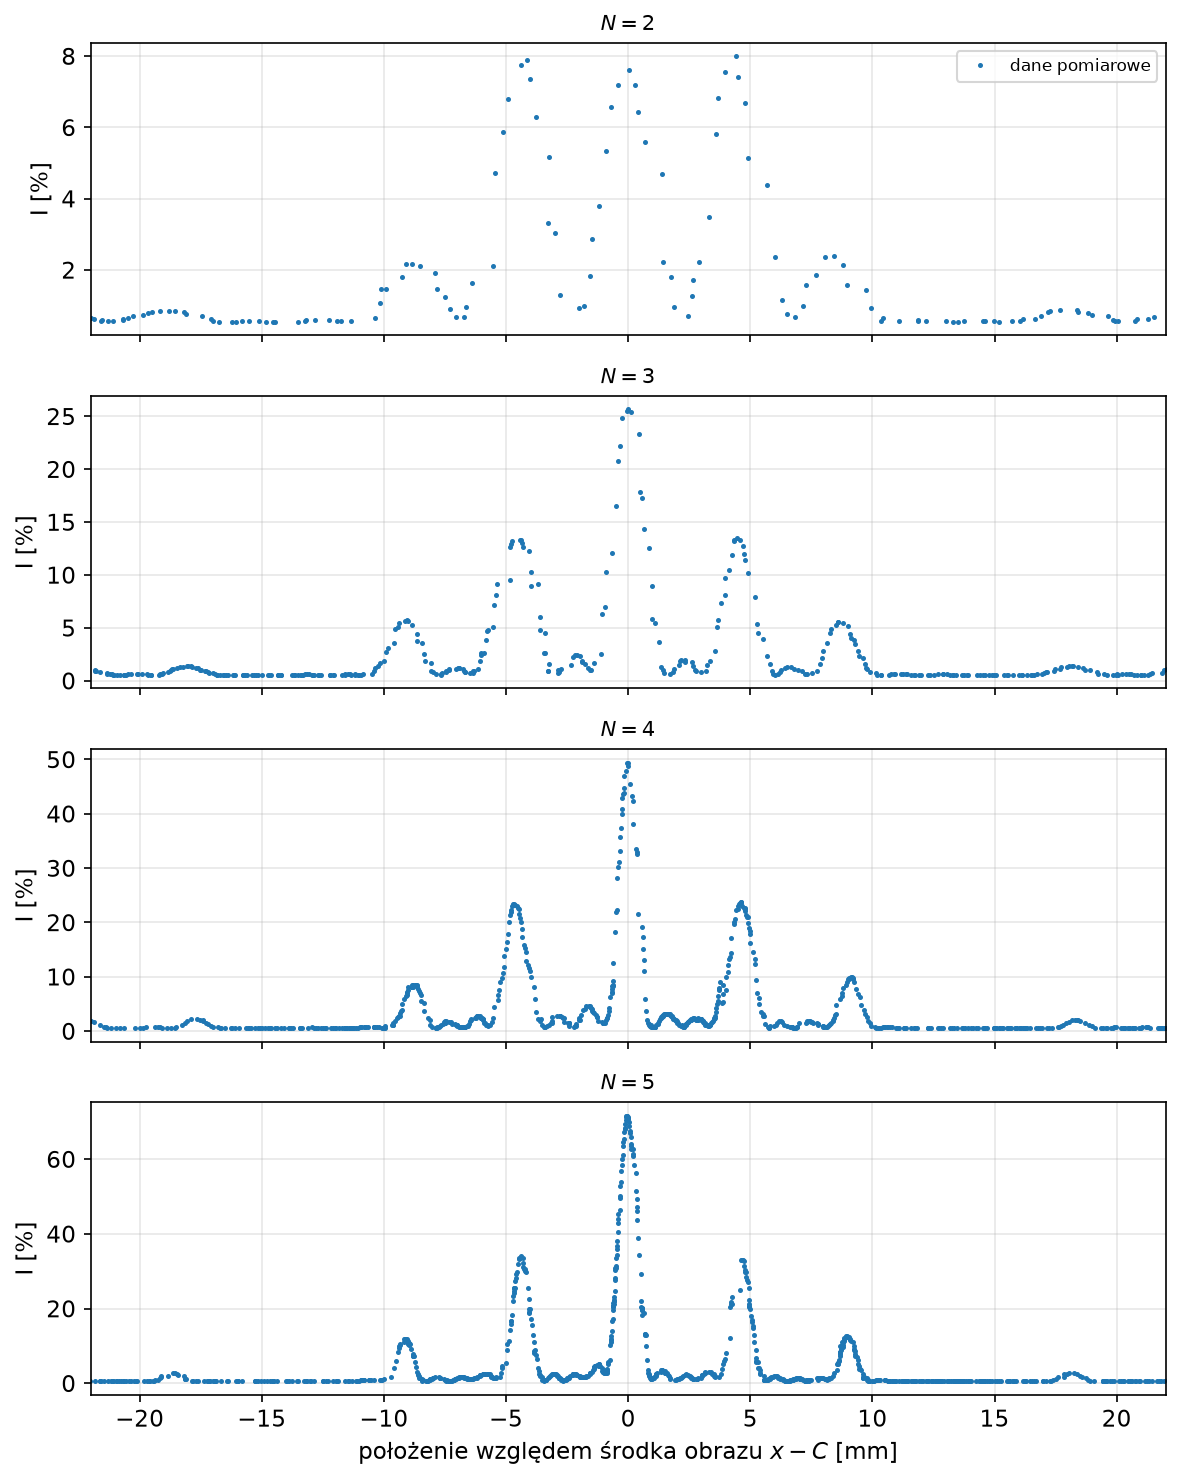

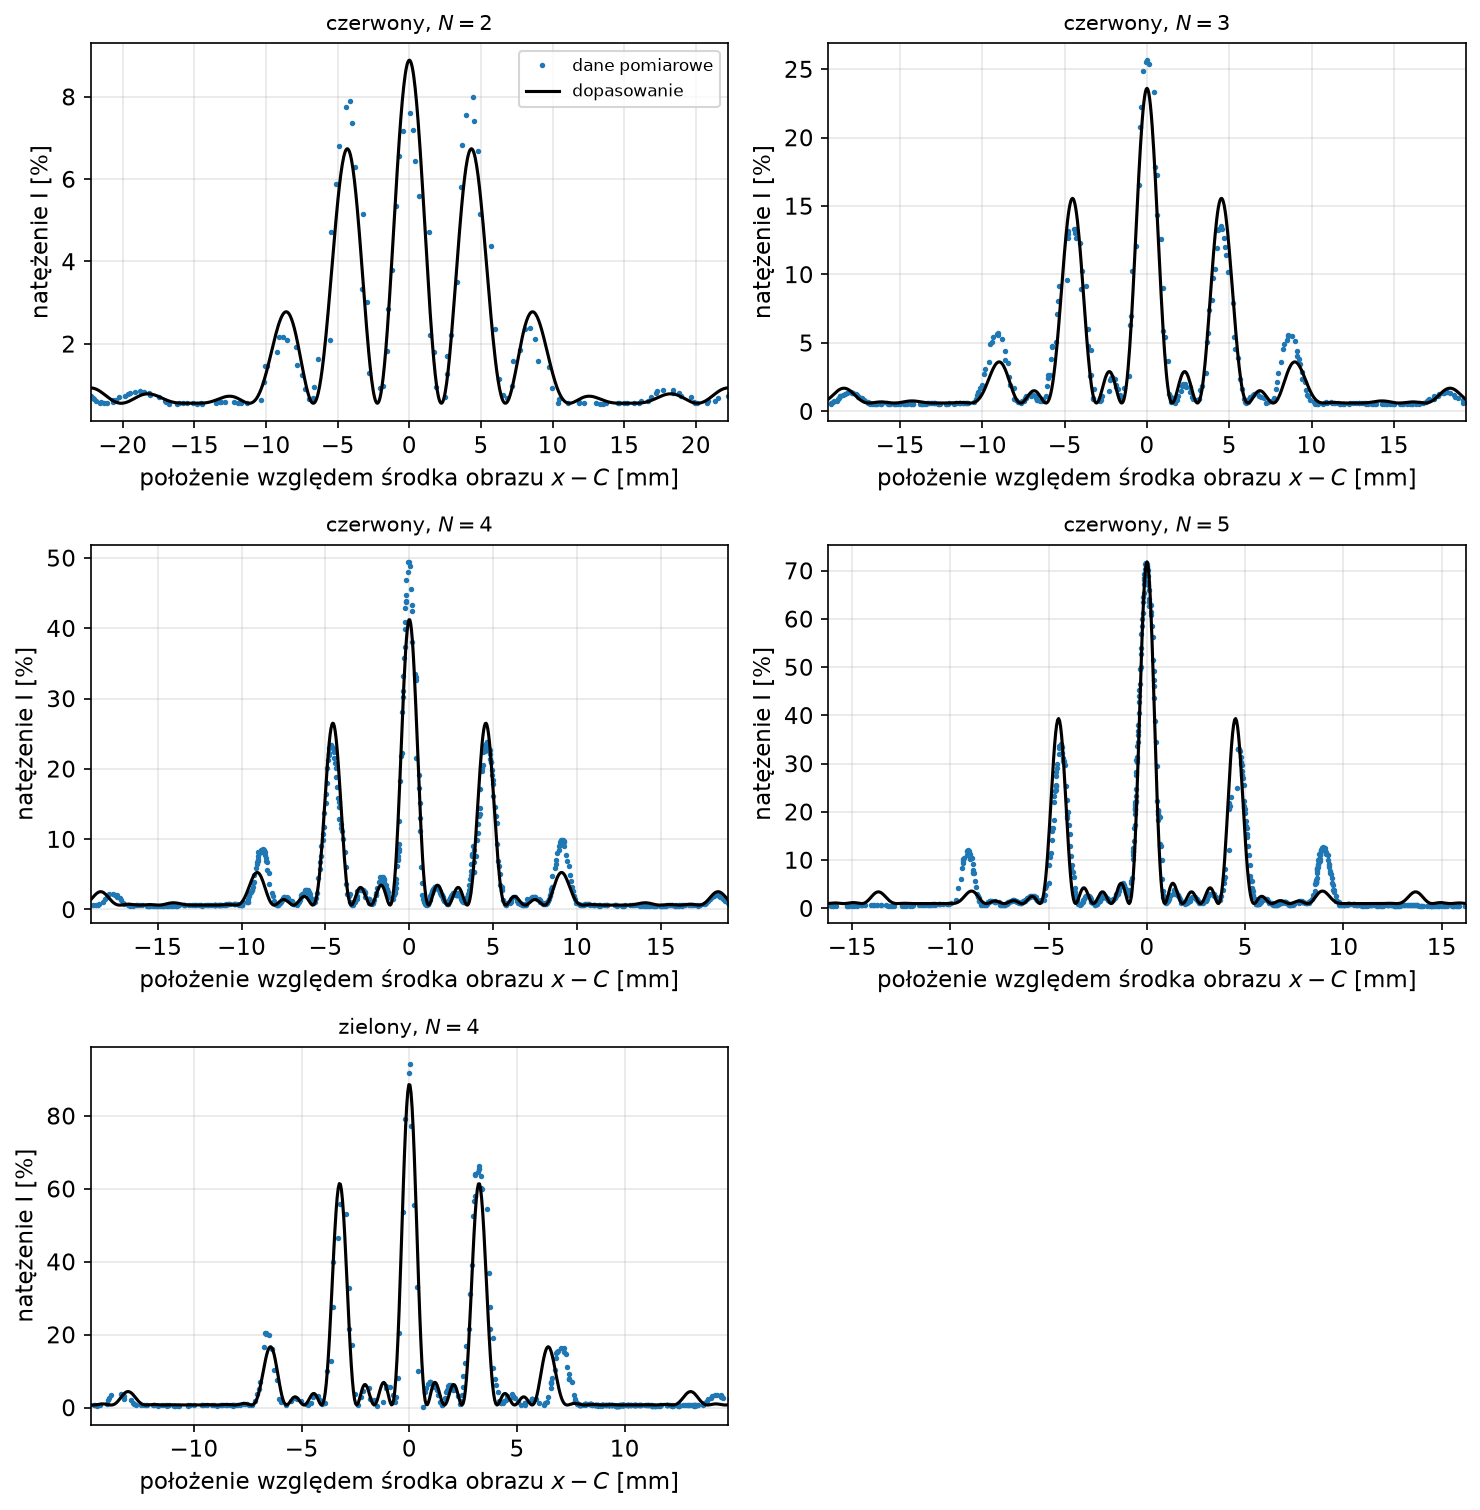

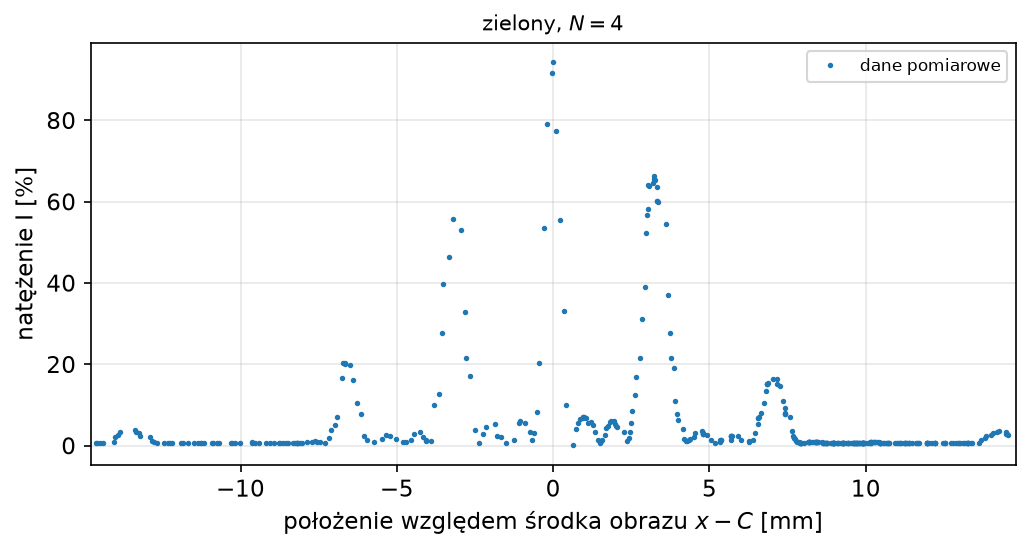

In [18]:
fig, axs = plt.subplots(4, 1, figsize=(8, 10), sharex=True)
for ax, N in zip(axs, WIELE['red']):
    df, fit = wczytaj('red', f'multi_slit_N{N}_1.csv'), C_fit['red', N][0]
    ax.plot(df['x'] - fit['C'], df['I'], 'o', ms=1.4, color='tab:blue', label='dane pomiarowe')
    ax.set_ylabel('I [%]')
    ax.set_title(f'$N = {N}$', fontsize=10)
axs[-1].set_xlabel('położenie względem środka obrazu $x - C$ [mm]')
axs[-1].set_xlim(-22, 22)
axs[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig('multi_slit_red_raw.pdf')
plt.show()

poz = [(f'czerwony, $N = {N}$', wczytaj('red', f'multi_slit_N{N}_1.csv'), C_fit['red', N][0]) for N in WIELE['red']]
poz.append(('zielony, $N = 4$', wczytaj('green', 'multi_slit_N4_1.csv'), C_fit['green', 4][0]))
wykres_przejazdow(poz, 'multi_slit.pdf', True, zakres=1.5)
wykres_przejazdow(poz[-1:], 'multi_slit_green_raw.pdf', False, zakres=1.5)

### Obwiednia dyfrakcyjna układów wielu szczelin a pojedyncze szczeliny

Zgodnie z Dodatkiem B: dane znormalizowane do $[0, 1]$ (po odjęciu tła $b$ z dopasowania) i porównane
z rozkładem pojedynczych szczelin $a = 0{,}04$ i $0{,}08$ mm (czerwony).

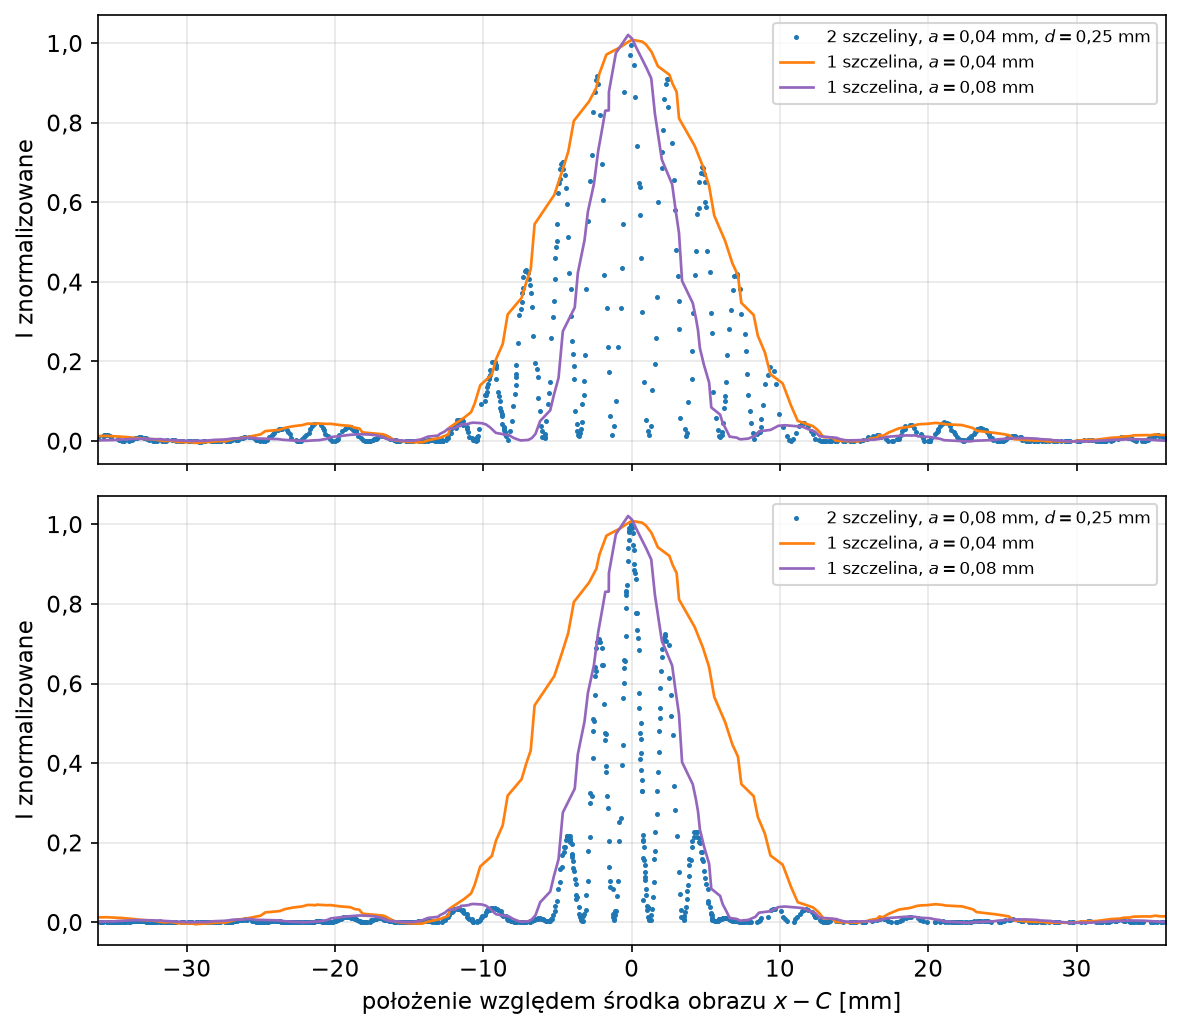

In [19]:
fig, axs = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
for ax, (tytul, df, fit) in zip(axs, [('2 szczeliny, $a = 0{,}04$ mm, $d = 0{,}25$ mm', wczytaj('red', plik_2(0.04, 0.25, 1)), B_fit['red', 0.04, 0.25][0]),
                                      ('2 szczeliny, $a = 0{,}08$ mm, $d = 0{,}25$ mm', wczytaj('red', plik_2(0.08, 0.25, 1)), B_fit['red', 0.08, 0.25][0])]):
    y = df['x'] - fit['C']
    ax.plot(y, (df['I'] - fit['b']) / fit['A'], 'o', ms=1.4, color='tab:blue', label=tytul)
    for a_nom, c in ((0.04, 'tab:orange'), (0.08, 'tab:purple')):
        d1, f1 = wczytaj('red', plik_1(a_nom, 1)), A_fit['red', a_nom, 1]
        ax.plot(d1['x'] - f1['C'], (d1['I'] - f1['b']) / f1['A'], '-', lw=1.3, color=c,
                label=f'1 szczelina, $a = {plm(a_nom)}$ mm')
    ax.set_ylabel('I znormalizowane')
    ax.legend(fontsize=8)
axs[-1].set_xlabel('położenie względem środka obrazu $x - C$ [mm]')
axs[-1].set_xlim(-36, 36)
fig.tight_layout()
fig.savefig('envelope_comparison.pdf')
plt.show()

## Część D — zmiana odległości szczeliny od detektora

Szczelina $a = 0{,}02$ mm, czerwony, $D = 400,\ 500,\ 1000$ mm (po jednym przejeździe) i $D = 900$ mm (A1, trzy przejazdy).
Odległość minimów $s = \lambda D/a$ powinna rosnąć liniowo z $D$ i przechodzić przez zero. Dwie metody:
$s = \pi/B_a$ z dopasowania i $s$ z regresji położeń minimów, dla każdego $D$; potem regresja liniowa $s(D)$:
nachylenie $\lambda/a$, wyraz wolny sprawdza przesunięcie zera skali ławy.

In [20]:
ODL = [('single_slit_a02_D400.csv', 400), ('single_slit_a02_D500.csv', 500)] + \
      [(plik_1(0.02, k), 900) for k in (1, 2, 3)] + [('single_slit_a02_D1000.csv', 1000)]
wiersze = []
D_fit = {}
for plik, D in ODL:
    df = wczytaj('red', plik)
    fit = dopasuj(df)
    reg = regresja(minima_dyfrakcyjne(df, fit))
    D_fit[plik] = (df, fit, reg)
    wiersze.append(dict(plik=plik, D=df.attrs['D'], s_fit=np.pi / fit['Ba'], u_s_fit=np.pi * fit['u_Ba'] / fit['Ba'] ** 2,
                        s_reg=reg['s'], u_s_reg=reg['u_s'], n_min=reg['n'], rms_wzgl=fit['rms'] / fit['A']))
tab_D = pd.DataFrame(wiersze)
print(tab_D.to_string(index=False, float_format='%.4f'))

lam, u_lam = LAMBDA['red']
D_wyniki = {}
for met in ('fit', 'reg'):
    r = linregress(tab_D['D'], tab_D[f's_{met}'])
    a_D = lam / r.slope
    u_a_D = a_D * np.sqrt((r.stderr / r.slope) ** 2 + (u_lam / lam) ** 2 + (U_SKALA_X / SKALA_X) ** 2)
    D_wyniki[met] = (r, a_D, u_a_D)
    print(f'{met}: s = ({r.slope:.5f} ± {r.stderr:.5f}) D + ({r.intercept:.2f} ± {r.intercept_stderr:.2f}) mm   '
          f'→ a = λ / nachylenie = ({a_D:.4f} ± {u_a_D:.4f}) mm;  wyraz wolny / u = {abs(r.intercept) / r.intercept_stderr:.1f};  '
          f'ΔD = c / nachylenie = ({r.intercept / r.slope:.0f} ± {r.intercept_stderr / r.slope:.0f}) mm')

# tylko sesja 3 listopada (D = 400, 500, 1000 mm) — bez serii z 27 października
t3 = tab_D[tab_D['D'] != 900]
r3 = linregress(t3['D'], t3['s_fit'])
print(f'3.11, dopasowanie: s = ({r3.slope:.5f} ± {r3.stderr:.5f}) D + ({r3.intercept:.2f} ± {r3.intercept_stderr:.2f}) mm; '
      f'a = {lam / r3.slope:.4f} mm')

# realistyczna niepewność pojedynczego przejazdu: rozrzut trzech przejazdów przy D = 900 mm
s9 = tab_D[tab_D['D'] == 900]['s_fit']
print(f'D = 900: σ(s_fit) = {s9.std(ddof=1):.3f} mm wobec u z curve_fit {tab_D[tab_D["D"] == 900]["u_s_fit"].mean():.3f} mm '
      f'(×{s9.std(ddof=1) / tab_D[tab_D["D"] == 900]["u_s_fit"].mean():.1f})')

                     plik         D   s_fit  u_s_fit   s_reg  u_s_reg  n_min  rms_wzgl
 single_slit_a02_D400.csv  400.0000 12.0699   0.1611 11.9026   0.0647      9    0.0407
 single_slit_a02_D500.csv  500.0000 15.4601   0.2759 15.4597   0.1697      7    0.0505
    single_slit_a02_1.csv  900.0000 28.6385   0.1088 29.0841   0.4116      4    0.0125
    single_slit_a02_2.csv  900.0000 28.2064   0.1195 28.5649   0.3132      4    0.0129
    single_slit_a02_3.csv  900.0000 28.3434   0.1428 29.0641   0.3171      4    0.0153
single_slit_a02_D1000.csv 1000.0000 31.2114   0.4631 31.2434   0.2312      4    0.0566
fit: s = (0.03221 ± 0.00043) D + (-0.71 ± 0.35) mm   → a = λ / nachylenie = (0.0202 ± 0.0004) mm;  wyraz wolny / u = 2.0;  ΔD = c / nachylenie = (-22 ± 11) mm
reg: s = (0.03308 ± 0.00086) D + (-1.14 ± 0.69) mm   → a = λ / nachylenie = (0.0196 ± 0.0006) mm;  wyraz wolny / u = 1.7;  ΔD = c / nachylenie = (-35 ± 21) mm
3.11, dopasowanie: s = (0.03177 ± 0.00034) D + (-0.54 ± 0.23) mm; a = 0.0

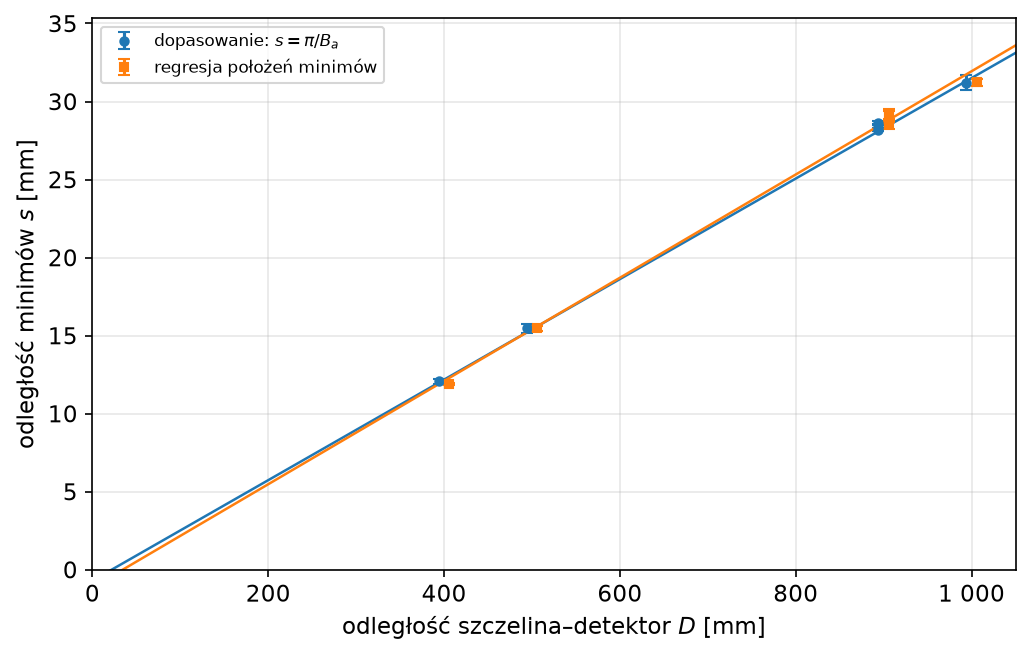

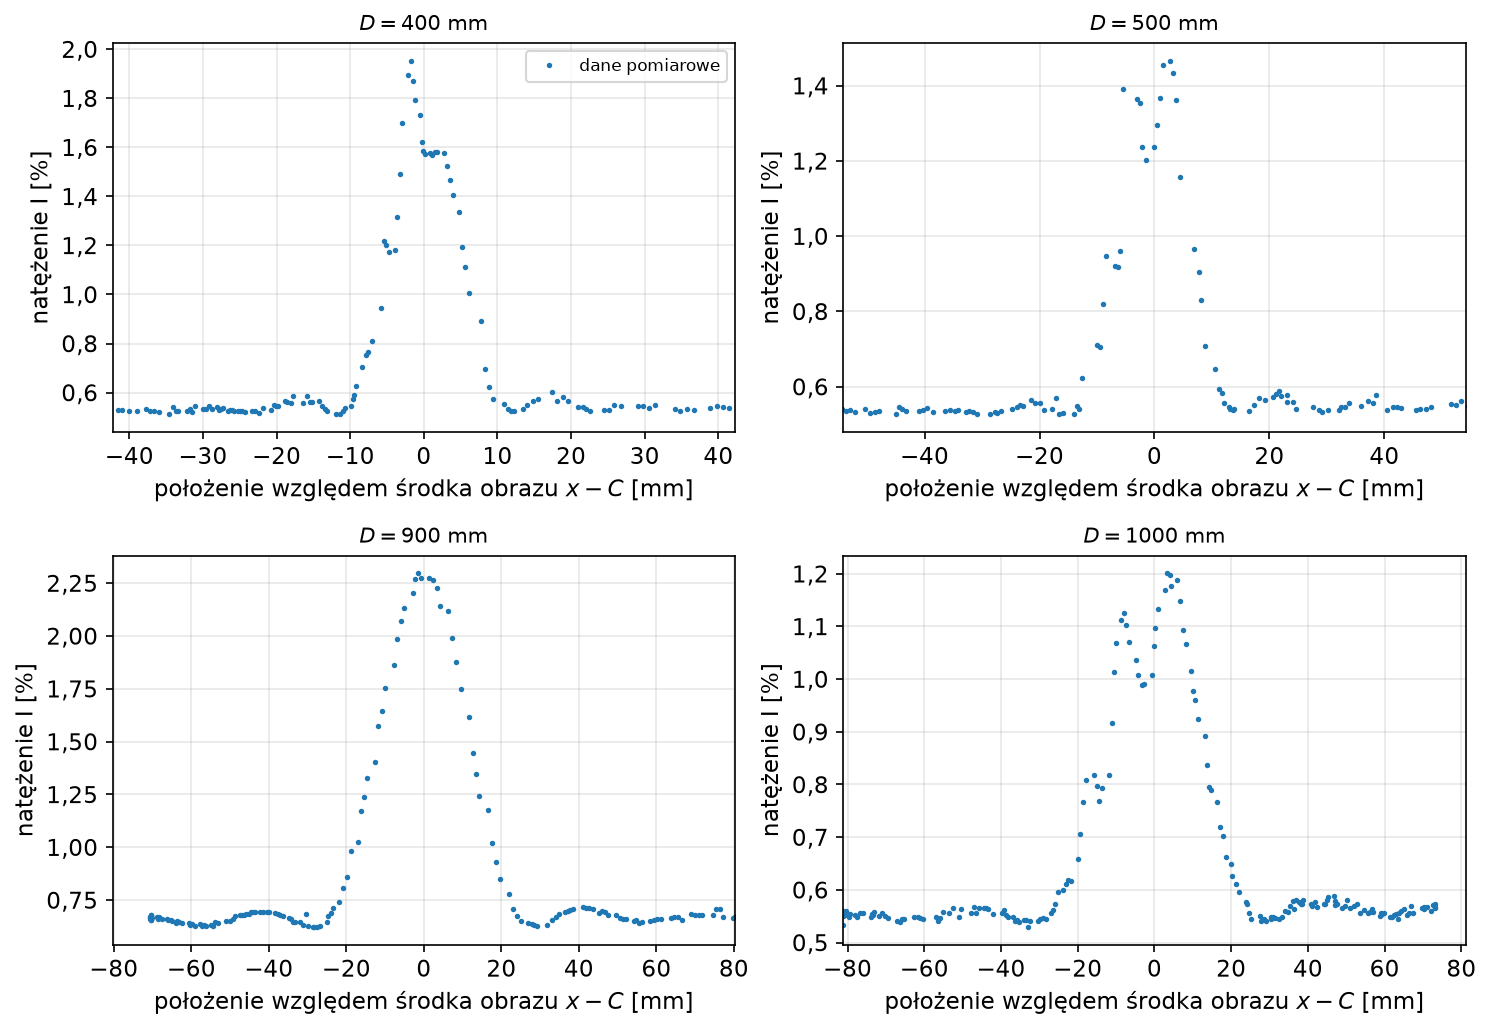

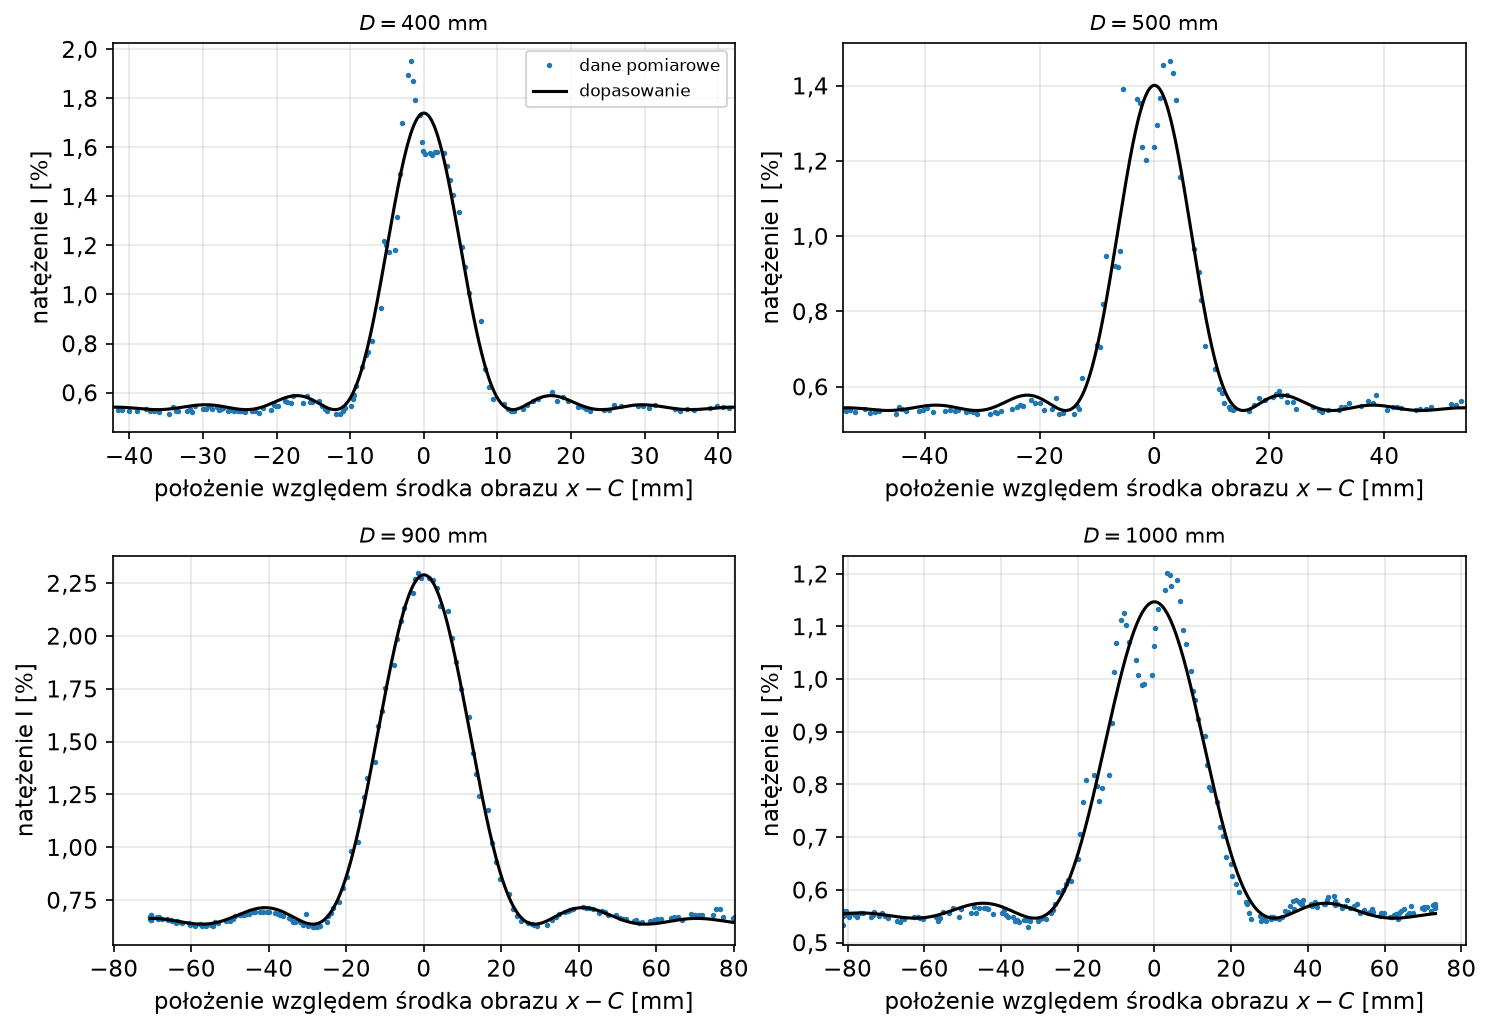

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
DD = np.linspace(0, 1050, 2)
for met, mk, c, et in (('fit', 'o', 'tab:blue', 'dopasowanie: $s = \\pi/B_a$'), ('reg', 's', 'tab:orange', 'regresja położeń minimów')):
    off = -6 if met == 'fit' else 6
    ax.errorbar(tab_D['D'] + off, tab_D[f's_{met}'], yerr=tab_D[f'u_s_{met}'], fmt=mk, ms=4, capsize=3, color=c, label=et)
    r = D_wyniki[met][0]
    ax.plot(DD, r.intercept + r.slope * DD, '-', lw=1.2, color=c)
ax.set_xlabel('odległość szczelina–detektor $D$ [mm]')
ax.set_ylabel('odległość minimów $s$ [mm]')
ax.set_xlim(0, 1050)
ax.set_ylim(0, None)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig('distance_scaling.pdf')
plt.show()

poz = [(f'$D = {D:.0f}$ mm', D_fit[p][0], D_fit[p][1]) for p, D in ODL if not p.endswith(('_2.csv', '_3.csv'))]
wykres_przejazdow(poz, 'distance_raw.pdf', False)
wykres_przejazdow(poz, 'distance.pdf', True)

## Część E — zmiana apertury czujnika

Dwa przejazdy z aperturami 0,1 i 1,5 mm (`single_slit_a02_aperture_*`). Pomiar zaplanowano dla szczeliny
$a = 0{,}04$ mm, ale szerokość obrazu w obu przejazdach odpowiada szczelinie $a = 0{,}02$ mm (porównanie $B_a$ z A1
i A2 niżej) — szczelina z części D została w uchwycie. Pliki przemianowano z `single_slit_a04_aperture_*`.
Pomiarem odniesienia jest A1 ($a = 0{,}02$ mm, apertura zwykła — w rejestrze nieopisana).

                           plik              apertura     Ba   u_Ba  a_fit      A  tlo_b  rms_wzgl  n_min
          single_slit_a02_1.csv                zwykła 0.1097 0.0004 0.0204 1.6533 0.6359    0.0125      4
          single_slit_a02_2.csv                zwykła 0.1114 0.0005 0.0207 1.5924 0.6367    0.0129      4
          single_slit_a02_3.csv                zwykła 0.1108 0.0006 0.0206 1.5917 0.6349    0.0153      4
          single_slit_a04_1.csv zwykła (A2, a = 0,04) 0.2184 0.0005 0.0407 7.0262 0.6376    0.0080      9
          single_slit_a04_2.csv zwykła (A2, a = 0,04) 0.2121 0.0007 0.0395 8.5423 0.6314    0.0102      9
          single_slit_a04_3.csv zwykła (A2, a = 0,04) 0.2084 0.0008 0.0388 9.3021 0.6306    0.0121      9
single_slit_a02_aperture_01.csv                   0,1 0.1247 0.0010 0.0232 0.6560 0.5442    0.0598      4
single_slit_a02_aperture_15.csv                   1,5 0.1075 0.0009 0.0200 9.4287 1.8417    0.0702      4
apertura 0,1: B_a / B_a(zwykła) − 1 = +0.127; 

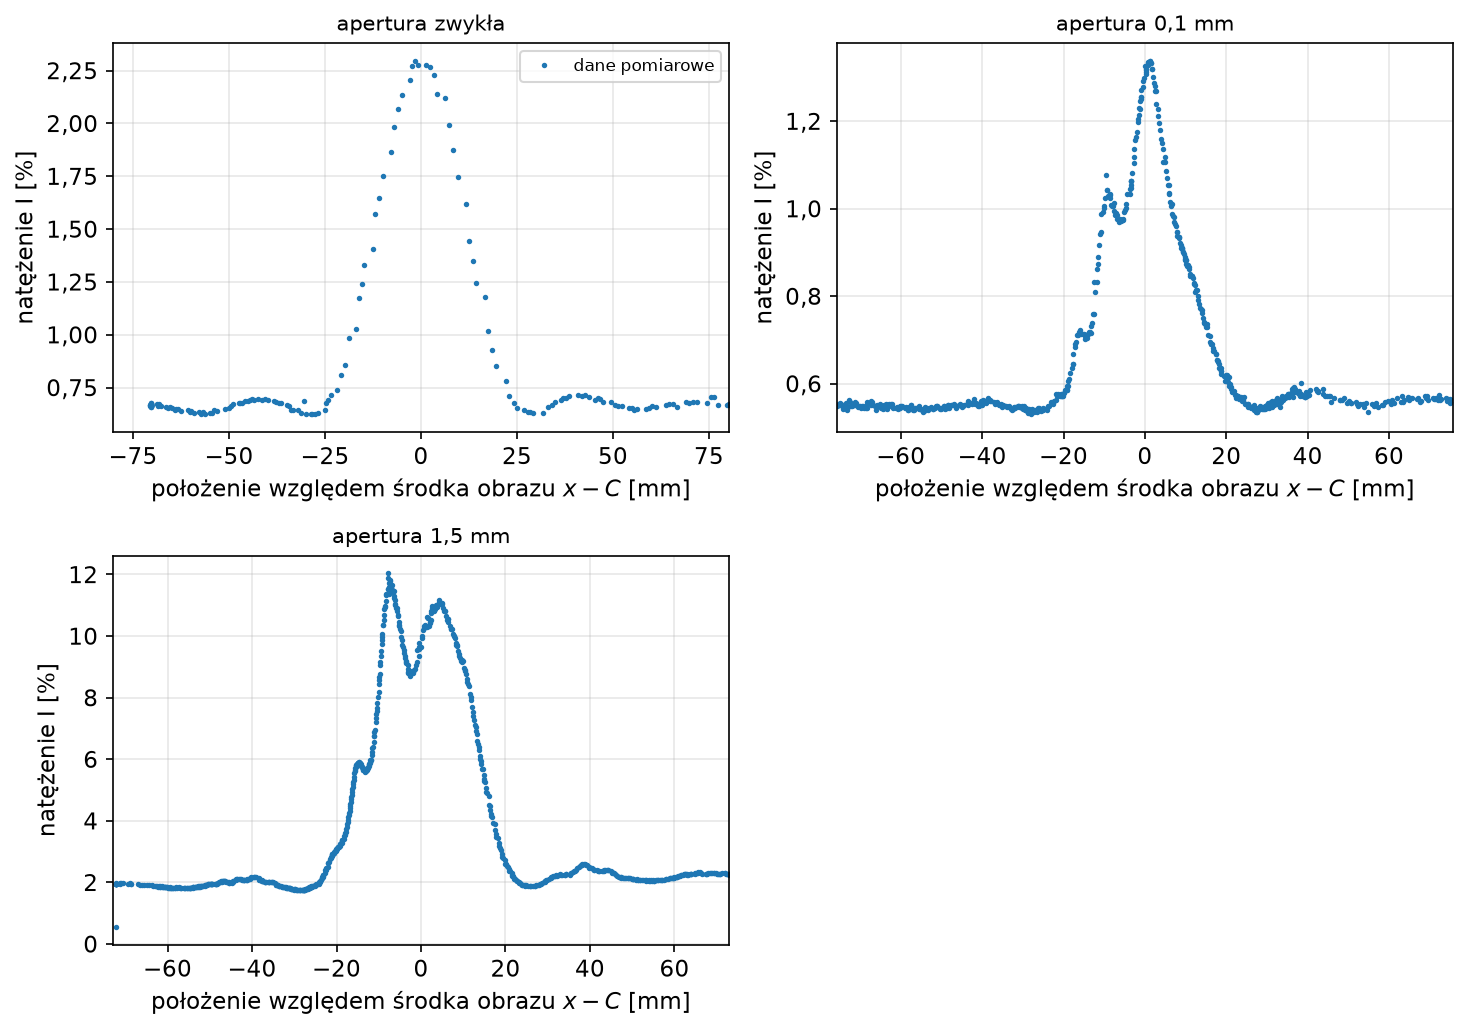

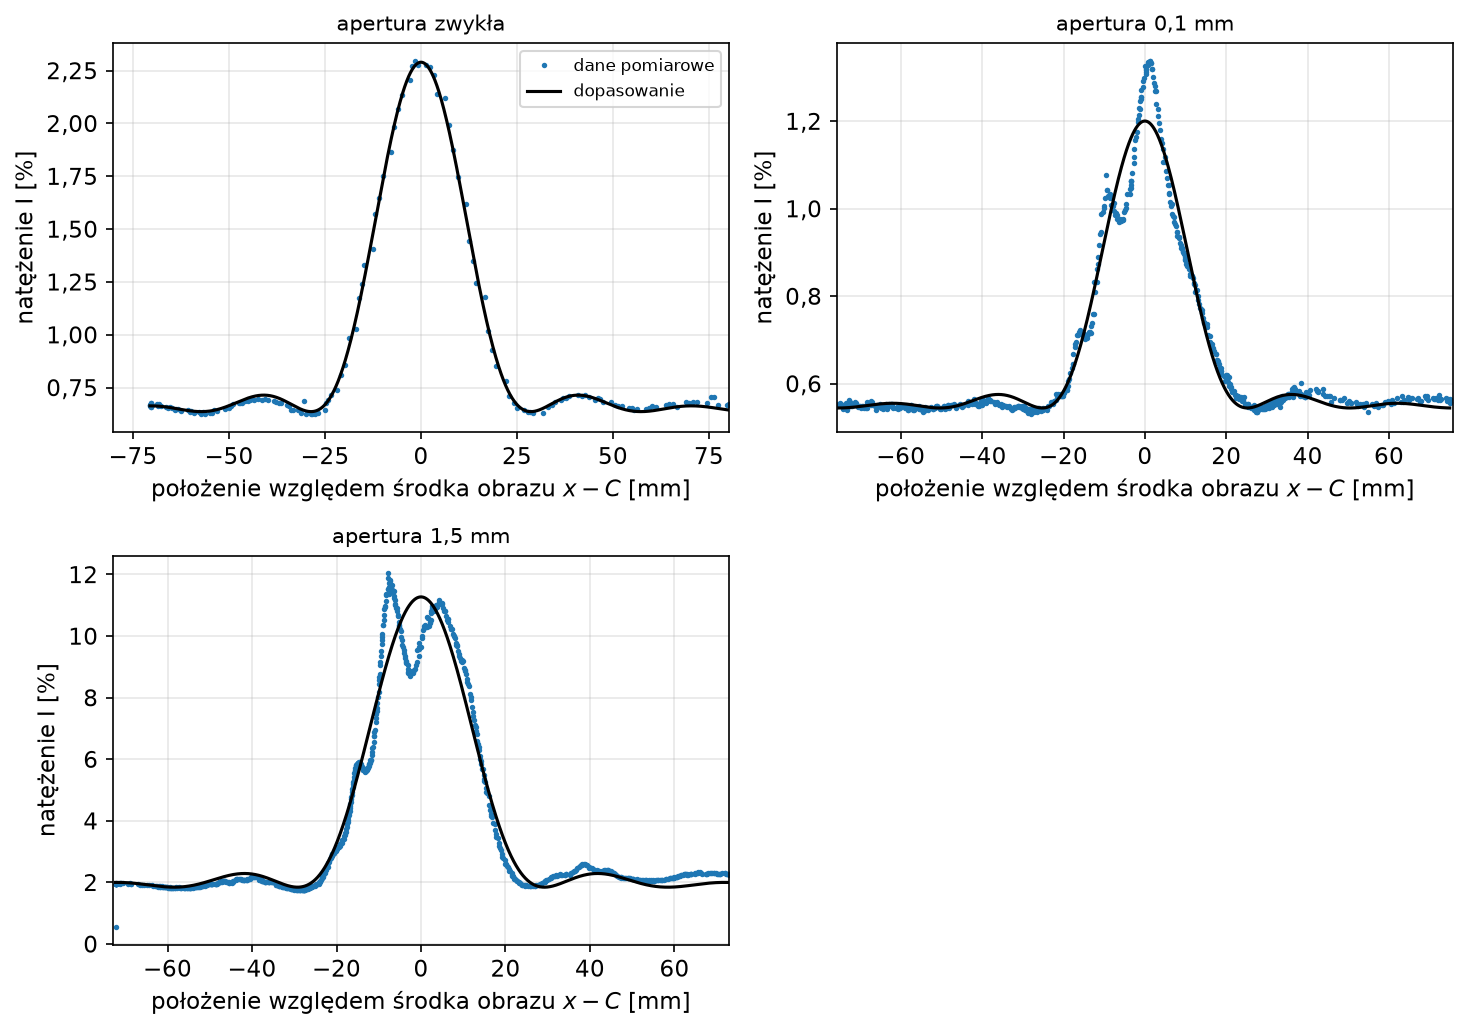

In [22]:
wiersze = []
E_fit = {}
for plik, opis in [(plik_1(0.02, k), 'zwykła') for k in (1, 2, 3)] + [(plik_1(0.04, k), 'zwykła (A2, a = 0,04)') for k in (1, 2, 3)] + \
                  [('single_slit_a02_aperture_01.csv', '0,1'), ('single_slit_a02_aperture_15.csv', '1,5')]:
    df = wczytaj('red', plik)
    fit = dopasuj(df)
    reg = regresja(minima_dyfrakcyjne(df, fit))
    E_fit[plik] = (df, fit, reg)
    wiersze.append(dict(plik=plik, apertura=opis, Ba=fit['Ba'], u_Ba=fit['u_Ba'],
                        a_fit=fit['Ba'] * lam * 900 / np.pi, A=fit['A'], tlo_b=fit['b'], rms_wzgl=fit['rms'] / fit['A'],
                        n_min=reg['n']))
tab_E = pd.DataFrame(wiersze)
print(tab_E.to_string(index=False, float_format='%.4f'))
zw = tab_E[tab_E['apertura'] == 'zwykła']
Ba_zw, s_Ba = zw['Ba'].mean(), zw['Ba'].std(ddof=1)
for ap in ('0,1', '1,5'):
    r = tab_E[tab_E['apertura'] == ap].iloc[0]
    print(f'apertura {ap}: B_a / B_a(zwykła) − 1 = {r.Ba / Ba_zw - 1:+.3f}; (B_a − B_zw)/σ(przejazdu) = {(r.Ba - Ba_zw) / s_Ba:+.1f}; '
          f'A/b = {r.A / r.tlo_b:.2f}, I_max/b = {r.A / r.tlo_b + 1:.2f}')
for ap in ('1,5',):
    r = tab_E[tab_E['apertura'] == ap].iloc[0]
    print(f'A(1,5)/A(zwykła) = {r.A / zw["A"].mean():.2f}, b(1,5)/b(zwykła) = {r.tlo_b / zw["tlo_b"].mean():.2f}')
print(f'σ tła (czerwony) = {wczytaj("red", "background.csv")["I"].std():.4f} %')

poz = [('apertura zwykła', *E_fit[plik_1(0.02, 1)][:2]), ('apertura 0,1 mm', *E_fit['single_slit_a02_aperture_01.csv'][:2]),
       ('apertura 1,5 mm', *E_fit['single_slit_a02_aperture_15.csv'][:2])]
wykres_przejazdow(poz, 'aperture_raw.pdf', False)
wykres_przejazdow(poz, 'aperture.pdf', True)

In [23]:
# Sprawdzenie szerokości apertur z natężenia: obraz (s ≈ 28 mm) jest dużo szerszy od apertury, więc zebrana moc ∝ w
A_ = {r.apertura: r.A for r in tab_E.itertuples()}
A_zw = zw['A'].mean()
print(f"A(1,5)/A(0,1) = {A_['1,5'] / A_['0,1']:.1f}  →  w = 0,1 mm × {A_['1,5'] / A_['0,1']:.1f} = {0.1 * A_['1,5'] / A_['0,1']:.2f} mm "
      f"(stosunek szerokości 1,5/0,1 = 15)")
print(f"apertura zwykła: w ≈ 0,1 mm × A(zwykła)/A(0,1) = {0.1 * A_zw / A_['0,1']:.2f} mm (inna sesja — tylko orientacyjnie)")

A(1,5)/A(0,1) = 14.4  →  w = 0,1 mm × 14.4 = 1.44 mm (stosunek szerokości 1,5/0,1 = 15)
apertura zwykła: w ≈ 0,1 mm × A(zwykła)/A(0,1) = 0.25 mm (inna sesja — tylko orientacyjnie)


## Kierunek przejazdu

Przejazdy wykonywano na przemian w obu kierunkach. Opóźnienie między odczytem $x$ i $I$ (dwa osobne zapytania
Bluetooth) albo luz enkodera przesuwałyby obraz o $\Delta C \propto v$ w kierunku ruchu: środek $C$ przejazdów →
i ← tego samego układu różniłby się o $2 v \tau$. Odstępy (a więc $a$, $d$) od stałego przesunięcia nie zależą.

In [24]:
# Dla każdego układu z trzema przejazdami: C(→) − C(←) wobec średniej prędkości
zest = {L: zestawienie(L).set_index('plik') for L in LAMBDA}
kier = []
def dodaj(L, pliki, fity):
    dirs = [REJ[L].loc[p, 'direction'] for p in pliki]
    Cs = [f['C'] for f in fity]
    vs = [zest[L].loc[p, 'v'] for p in pliki]
    for i in range(len(pliki)):
        for j in range(i + 1, len(pliki)):
            if dirs[i] != dirs[j]:
                dC = (Cs[i] - Cs[j]) * np.sign(dirs[i])          # C(→) − C(←)
                kier.append(dict(laser=L, uklad=pliki[i][:-6], dC=dC, v=(vs[i] + vs[j]) / 2))
for L, lista in SZCZELINY.items():
    for a in lista:
        dodaj(L, [plik_1(a, k) for k in (1, 2, 3)], [A_fit[L, a, k] for k in (1, 2, 3)])
for L, lista in PODWOJNE.items():
    for a, d in lista:
        dodaj(L, [plik_2(a, d, k) for k in (1, 2, 3)], B_fit[L, a, d])
for L, lista in WIELE.items():
    for N in lista:
        dodaj(L, [f'multi_slit_N{N}_{k}.csv' for k in (1, 2, 3)], C_fit[L, N])
tab_kier = pd.DataFrame(kier)
rk = linregress(tab_kier['v'], tab_kier['dC'])
print(tab_kier.groupby(['laser', 'uklad']).agg(dC=('dC', 'mean'), v=('v', 'mean')).to_string(float_format='%.3f'))
print(f'\n{len(tab_kier)} par: ΔC = ({rk.slope:.3f} ± {rk.stderr:.3f}) s · v + ({rk.intercept:.3f} ± {rk.intercept_stderr:.3f}) mm, '
      f'R² = {rk.rvalue ** 2:.2f};  średnio ΔC = {tab_kier["dC"].mean():.3f} mm, σ = {tab_kier["dC"].std(ddof=1):.3f} mm')
print(f'opóźnienie τ = nachylenie/2 = {rk.slope / 2 * 1000:.0f} ± {rk.stderr / 2 * 1000:.0f} ms')

                             dC     v
laser uklad                          
green double_slit_a08_d25 0.354 0.679
      double_slit_a08_d50 0.628 0.592
      multi_slit_N4       0.089 0.554
      single_slit_a04     1.655 1.885
      single_slit_a08     0.383 2.094
red   double_slit_a04_d25 1.351 1.299
      double_slit_a04_d50 0.156 0.463
      double_slit_a08_d25 1.553 1.139
      double_slit_a08_d50 0.034 0.471
      multi_slit_N2       1.305 1.890
      multi_slit_N3       0.764 0.867
      multi_slit_N4       0.952 0.654
      multi_slit_N5       0.335 0.633
      single_slit_a02     3.941 7.659
      single_slit_a04     1.879 4.045
      single_slit_a08     2.276 2.631
      single_slit_a16     1.987 1.387

34 par: ΔC = (0.503 ± 0.096) s · v + (0.299 ± 0.236) mm, R² = 0.46;  średnio ΔC = 1.155 mm, σ = 1.329 mm
opóźnienie τ = nachylenie/2 = 252 ± 48 ms


In [25]:
# Wpływ kierunku na wyznaczane B: względna różnica średnich B(→)/B(←) − 1 w każdym układzie
def roznica_kier(L, pliki, fity, klucz):
    dirs = np.array([REJ[L].loc[p, 'direction'] for p in pliki]); B = np.array([f[klucz] for f in fity])
    if (dirs > 0).any() and (dirs < 0).any():
        return B[dirs > 0].mean() / B[dirs < 0].mean() - 1
wk = {'a': [], 'd': []}
for L, lista in SZCZELINY.items():
    for a in lista:
        wk['a'].append(roznica_kier(L, [plik_1(a, k) for k in (1, 2, 3)], [A_fit[L, a, k] for k in (1, 2, 3)], 'Ba'))
for L, lista in PODWOJNE.items():
    for a, d in lista:
        pl_ = [plik_2(a, d, k) for k in (1, 2, 3)]
        wk['a'].append(roznica_kier(L, pl_, B_fit[L, a, d], 'Ba')); wk['d'].append(roznica_kier(L, pl_, B_fit[L, a, d], 'Bd'))
for L, lista in WIELE.items():
    for N in lista:
        wk['d'].append(roznica_kier(L, [f'multi_slit_N{N}_{k}.csv' for k in (1, 2, 3)], C_fit[L, N], 'Bd'))
for q, v in wk.items():
    v = np.array([x for x in v if x is not None])
    print(f'{q}: B(→)/B(←) − 1 = ({100 * v.mean():+.2f} ± {100 * v.std(ddof=1) / np.sqrt(len(v)):.2f}) %  ({len(v)} układów; '
          f'rozrzut {100 * v.std(ddof=1):.1f} %)')

a: B(→)/B(←) − 1 = (-0.71 ± 0.89) %  (12 układów; rozrzut 3.1 %)
d: B(→)/B(←) − 1 = (+0.10 ± 0.78) %  (11 układów; rozrzut 2.6 %)


## Zestawienie wyników i porównanie z wartościami producenta

Dla każdej wielkości: wynik z niepewnością, stosunek do wartości producenta $k = q/q_\text{nom}$
i odchylenie od niej w jednostkach niepewności $|q - q_\text{nom}|/u(q)$ (wartości producenta bez niepewności).

In [26]:
tab = pd.DataFrame(WYNIKI)
tab['k'] = tab['q'] / tab['nom']
tab['odch_sigma'] = (tab['q'] - tab['nom']).abs() / tab['u']
pd.set_option('display.width', 200)
print(tab[['laser', 'uklad', 'wielkosc', 'metoda', 'q', 'u', 'u_A', 'u_sys', 'nom', 'k', 'odch_sigma']].to_string(index=False, float_format='%.4f'))

laser                               uklad wielkosc      metoda      q      u    u_A  u_sys    nom      k  odch_sigma
  red               1 szczelina, a = 0.02        a dopasowanie 0.0206 0.0004 0.0001 0.0004 0.0200 1.0301      1.4320
  red               1 szczelina, a = 0.02        a    regresja 0.0202 0.0004 0.0002 0.0004 0.0200 1.0120      0.5649
  red               1 szczelina, a = 0.04        a dopasowanie 0.0397 0.0011 0.0007 0.0008 0.0400 0.9916      0.3184
  red               1 szczelina, a = 0.04        a    regresja 0.0396 0.0009 0.0005 0.0008 0.0400 0.9891      0.4679
  red               1 szczelina, a = 0.08        a dopasowanie 0.0790 0.0016 0.0005 0.0015 0.0800 0.9877      0.6041
  red               1 szczelina, a = 0.08        a    regresja 0.0789 0.0016 0.0004 0.0015 0.0800 0.9861      0.6990
  red               1 szczelina, a = 0.16        a dopasowanie 0.1545 0.0036 0.0019 0.0030 0.1600 0.9653      1.5487
  red               1 szczelina, a = 0.16        a    regresja 0

### Wspólny czynnik skali

Wszystkie wielkości — szerokości $a$ czterech różnych szczelin i odległości $d$ trzech układów — są większe
od wartości producenta o prawie ten sam czynnik $k$. Szerokości i odległości szczelin są od siebie niezależne,
więc taki sam względny błąd we wszystkich wskazuje na wspólny czynnik w $a = \lambda D/s$, czyli $\lambda$,
$D$ albo skalę położenia $x$. $D$ nie może być błędne o ~80 % ($D = 900 \pm 14$ mm z odczytu ławy), a część D
pokazuje, że $a$ nie zależy od $D$ w zakresie 400–1000 mm. Najbardziej prawdopodobna jest skala $x$: położenie
skanera to liczba impulsów enkodera razy przelicznik z biblioteki `pasco`.

Czynnik z dopasowania (dokładniejszy, z całego rozkładu) — średnia ważona po wszystkich układach danego lasera.
Do średniej wchodzi tylko niepewność statystyczna (typu A) — część systematyczna ($\lambda$, $D$) jest wspólna
i dokłada się na końcu.

czerwony: k = 1.009 ± 0.021  (stat. 0.002 × Birge 2.70; 16 wielkości, χ²/ν = 7.3; zakres k = 0.96–1.06); |k − 1|/u = 0.4
zielony : k = 1.036 ± 0.022  (stat. 0.003 × Birge 2.03; 7 wielkości, χ²/ν = 4.1; zakres k = 1.01–1.06); |k − 1|/u = 1.6


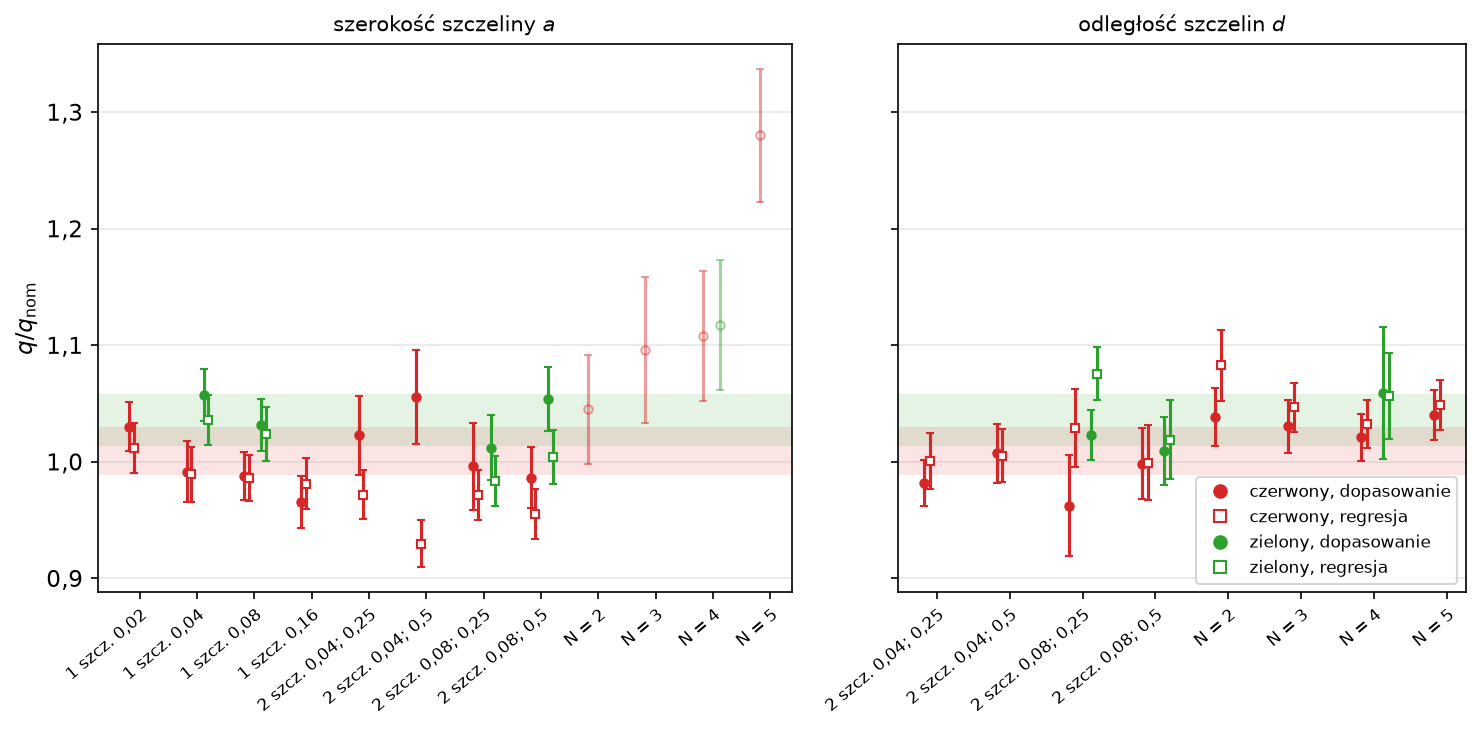

In [27]:
def srednia_wazona(q, u):
    w = 1 / np.asarray(u) ** 2
    return np.sum(w * q) / np.sum(w), np.sum(w) ** -0.5

K = {}
K_niezal = {}
for L in LAMBDA:
    t = tab[(tab['laser'] == L) & (tab['metoda'] == 'dopasowanie')]
    t = t[~((t['wielkosc'] == 'a') & t['uklad'].str.startswith('N ='))]   # a z układów N obciążone — poza średnią
    k, u_k_stat = srednia_wazona(t['k'], t['u_A'] / t['nom'])
    lam, u_lam = LAMBDA[L]
    chi2 = np.sum(((t['k'] - k) / (t['u_A'] / t['nom'])) ** 2)
    birge = np.sqrt(max(1, chi2 / (len(t) - 1)))          # skalowanie Birge'a — rozrzut ponad u_A
    u_k = np.hypot(u_k_stat * birge, k * np.sqrt((u_lam / lam) ** 2 + (14.14 / 900) ** 2 + (U_SKALA_X / SKALA_X) ** 2))
    K[L] = (k, u_k)
    K_niezal[L] = np.hypot(u_k_stat * birge, k * u_lam / lam)   # bez D i K_x — wspólnych dla obu laserów
    print(f'{NAZWA[L]:8s}: k = {k:.3f} ± {u_k:.3f}  (stat. {u_k_stat:.3f} × Birge {birge:.2f}; {len(t)} wielkości, '
          f'χ²/ν = {chi2 / (len(t) - 1):.1f}; zakres k = {t["k"].min():.2f}–{t["k"].max():.2f}); |k − 1|/u = {abs(k - 1) / u_k:.1f}')

def etykieta(u):
    u = u.replace('.', ',').replace(' szczelin, a = 0,04, d = 0,125', '')
    return u.replace('1 szczelina, a = ', '1 szcz. ').replace('2 szczeliny, a = ', '2 szcz. ').replace(', d = ', '; ')

fig, axs = plt.subplots(1, 2, figsize=(10, 5), sharey=True, gridspec_kw={'width_ratios': [11, 9]})
for ax, wielk, tyt in zip(axs, ('a', 'd'), ('szerokość szczeliny $a$', 'odległość szczelin $d$')):
    t = tab[tab['wielkosc'] == wielk]
    uklady = list(dict.fromkeys(t['uklad']))
    for j, u in enumerate(uklady):
        for L, dx0 in (('red', -0.18), ('green', 0.12)):
            for met, mk, dx in (('dopasowanie', 'o', 0), ('regresja', 's', 0.08)):
                r = t[(t['uklad'] == u) & (t['laser'] == L) & (t['metoda'] == met)]
                if not len(r):
                    continue
                r = r.iloc[0]
                poza = wielk == 'a' and u.startswith('N =')
                ax.errorbar(j + dx0 + dx, r['k'], yerr=r['u'] / r['nom'], fmt=mk, ms=4, capsize=2, color=KOLOR[L],
                            mfc='white' if met == 'regresja' else ('none' if poza else KOLOR[L]), alpha=0.45 if poza else 1)
    for L in LAMBDA:
        ax.axhspan(K[L][0] - K[L][1], K[L][0] + K[L][1], color=KOLOR[L], alpha=0.12, lw=0)
    ax.set_xticks(range(len(uklady)))
    ax.set_xticklabels([etykieta(u) for u in uklady], fontsize=8, rotation=40, ha='right', rotation_mode='anchor')
    ax.set_title(tyt, fontsize=10)
    ax.grid(axis='x', visible=False)
axs[0].set_ylabel('$q / q_\\mathrm{nom}$')
from matplotlib.lines import Line2D
uchwyty = [Line2D([], [], color=KOLOR[L], marker=mk, ls='', mfc=KOLOR[L] if f else 'white', label=f'{NAZWA[L]}, {met}')
           for L in LAMBDA for met, mk, f in (('dopasowanie', 'o', True), ('regresja', 's', False))]
axs[1].legend(handles=uchwyty, fontsize=8, loc='lower right')
fig.tight_layout()
fig.savefig('scale_factor.pdf')
plt.show()


In [28]:
dk = K['green'][0] - K['red'][0]
print(f"k_green − k_red = {dk:.3f} ± {np.hypot(K_niezal['red'], K_niezal['green']):.3f}  →  "
      f"{abs(dk) / np.hypot(K_niezal['red'], K_niezal['green']):.1f} σ (tylko λ i część statystyczna; D i K_x wspólne)")

k_green − k_red = 0.027 ± 0.015  →  1.7 σ (tylko λ i część statystyczna; D i K_x wspólne)


## Laser czerwony a zielony — długość fali czerwonego

Te same szczeliny zmierzono obydwoma laserami. Parametr $B = \pi q/(\lambda D)$ (w jednostkach skali skanera)
zależy od $\lambda$, ale czynnik skali $x$ i $D$ są wspólne, więc się skracają:

$$\lambda_\text{red} = \lambda_\text{green}\,\frac{B^\text{green}}{B^\text{red}}.$$

Z każdej pary (ten sam układ, ta sama wielkość) iloraz średnich $B$ z trzech przejazdów, z niepewnością
z rozrzutu przejazdów; wynik końcowy — średnia ważona po parach, plus niepewność $\lambda_\text{green}$.

In [29]:
def B_srednie(fity, klucz):
    v = np.array([f[klucz] for f in fity])
    return v.mean(), v.std(ddof=1) / np.sqrt(len(v))

pary = []
for a_nom in (0.04, 0.08):
    pary.append((f'1 szczelina a = {a_nom}', 'Ba', [A_fit['red', a_nom, k] for k in (1, 2, 3)], [A_fit['green', a_nom, k] for k in (1, 2, 3)]))
for d_nom in (0.25, 0.5):
    for kl in ('Ba', 'Bd'):
        pary.append((f'2 szczeliny a = 0.08, d = {d_nom}', kl, B_fit['red', 0.08, d_nom], B_fit['green', 0.08, d_nom]))
for kl in ('Ba', 'Bd'):
    pary.append(('N = 4 szczelin', kl, C_fit['red', 4], C_fit['green', 4]))

lam_g, u_lam_g = LAMBDA['green']
w = []
for opis, kl, fr, fg in pary:
    Br, uBr = B_srednie(fr, kl)
    Bg, uBg = B_srednie(fg, kl)
    R = Bg / Br
    uR = R * np.hypot(uBr / Br, uBg / Bg)
    w.append(dict(uklad=opis, B=kl, B_red=Br, B_green=Bg, lam_red=lam_g * R * 1e6, u_stat=lam_g * uR * 1e6))
tab_lam = pd.DataFrame(w)
print(tab_lam.to_string(index=False, float_format='%.4f'))
# B_a i B_d jednego układu pochodzą z tych samych przejazdów — nie są niezależne: jeden wynik na układ (średnia)
tab_uk = tab_lam.groupby('uklad', sort=False).agg(lam_red=('lam_red', 'mean'), u_stat=('u_stat', lambda v: np.sqrt(np.mean(v ** 2)))).reset_index()
tab_uk['u_stat'] *= t68(3)
print(tab_uk.to_string(index=False, float_format='%.1f'))
lam_r, u_stat = srednia_wazona(tab_uk['lam_red'], tab_uk['u_stat'])
chi2 = np.sum(((tab_uk['lam_red'] - lam_r) / tab_uk['u_stat']) ** 2)
u_stat_rozrzut = tab_uk['lam_red'].std(ddof=1) / np.sqrt(len(tab_uk))
u_stat = max(u_stat, u_stat_rozrzut)
u_lam_r = np.hypot(u_stat, lam_r * u_lam_g / lam_g)
lam_tab, u_lam_tab = LAMBDA['red'][0] * 1e6, LAMBDA['red'][1] * 1e6
print(f'\nλ_red = ({lam_r:.1f} ± {u_lam_r:.1f}) nm  (stat. {u_stat:.1f} nm — większa z: średnia ważona / rozrzut układów; '
      f'χ²/ν = {chi2 / (len(tab_uk) - 1):.2f}; u od λ_green {lam_r * u_lam_g / lam_g:.1f} nm)')
print(f'tabliczka: {lam_tab:.0f} ± {u_lam_tab:.0f} nm → |Δ|/u = {abs(lam_r - lam_tab) / np.hypot(u_lam_r, u_lam_tab):.1f};  '
      f'skrypt 640 nm → |Δ|/u = {abs(lam_r - 640) / u_lam_r:.1f}')

                         uklad  B  B_red  B_green  lam_red  u_stat
          1 szczelina a = 0.04 Ba 0.2130   0.2866 692.9584  9.9478
          1 szczelina a = 0.08 Ba 0.4243   0.5592 678.6287  4.9901
2 szczeliny a = 0.08, d = 0.25 Ba 0.4279   0.5487 660.4512 18.3656
2 szczeliny a = 0.08, d = 0.25 Bd 1.2920   1.7335 690.9847 21.5467
 2 szczeliny a = 0.08, d = 0.5 Ba 0.4237   0.5715 694.5846 12.7917
 2 szczeliny a = 0.08, d = 0.5 Bd 2.6808   3.4199 656.9883 15.1925
                N = 4 szczelin Ba 0.2380   0.3029 655.5141 32.3390
                N = 4 szczelin Bd 0.6853   0.8972 674.3003 25.3191
                         uklad  lam_red  u_stat
          1 szczelina a = 0.04    693.0    13.1
          1 szczelina a = 0.08    678.6     6.6
2 szczeliny a = 0.08, d = 0.25    675.7    26.5
 2 szczeliny a = 0.08, d = 0.5    675.8    18.6
                N = 4 szczelin    664.9    38.4

λ_red = (680.4 ± 8.6) nm  (stat. 5.4 nm — większa z: średnia ważona / rozrzut układów; χ²/ν = 0.31; u od λ_g

In [30]:
# Porównanie mierzy tylko stosunek długości fal
R_mier, u_R_mier = lam_r / (lam_g * 1e6), u_stat / (lam_g * 1e6)
R_tab = LAMBDA['red'][0] / LAMBDA['green'][0]
u_R_tab = R_tab * np.hypot(LAMBDA['red'][1] / LAMBDA['red'][0], LAMBDA['green'][1] / LAMBDA['green'][0])
print(f'λ_red/λ_green: zmierzone {R_mier:.3f} ± {u_R_mier:.3f}, z tabliczek {R_tab:.3f} ± {u_R_tab:.3f}; '
      f'różnica {100 * (R_mier / R_tab - 1):.1f} %, {abs(R_mier - R_tab) / np.hypot(u_R_mier, u_R_tab):.1f} σ')
print(f'gdyby czerwony był zgodny z tabliczką: λ_green = {650 / R_mier:.0f} nm; gdyby zielony: λ_red = {515 * R_mier:.0f} nm')
print(f'z = |λ_red − 650| / sqrt(u² + 5²) = {abs(lam_r - 650):.1f} / sqrt({u_lam_r:.1f}² + 5²) = {abs(lam_r - 650) / np.hypot(u_lam_r, 5):.2f}')

λ_red/λ_green: zmierzone 1.321 ± 0.011, z tabliczek 1.262 ± 0.016; różnica 4.7 %, 3.1 σ
gdyby czerwony był zgodny z tabliczką: λ_green = 492 nm; gdyby zielony: λ_red = 680 nm
z = |λ_red − 650| / sqrt(u² + 5²) = 30.4 / sqrt(8.6² + 5²) = 3.07


## Tabele do sprawozdania

Wiersze tabel LaTeX z wynikami końcowymi. Niepewność zaokrąglona do dwóch cyfr znaczących, wartość do tego
samego miejsca. Zgodność metod z różnic tych samych przejazdów, $\Delta_k = q_{\text{fit},k} - q_{\text{reg},k}$:
$z = |\bar\Delta| / u(\bar\Delta)$, $u(\bar\Delta) = t\,\sigma(\Delta)/\sqrt{n}$ — $\lambda$, $D$ i rozrzut między
przejazdami są wspólne dla obu metod i się znoszą.

In [31]:
def zaokr(q, u, cyfr=2):
    '''(q, u) jako napisy: u do `cyfr` cyfr znaczących, q do tego samego miejsca.'''
    rz = cyfr - 1 - int(np.floor(np.log10(u)))
    return f'{q:.{rz}f}', f'{u:.{rz}f}'

def wiersz_qu(q, u):
    a, b = zaokr(q, u)
    return f'{a} & {b}'

def z_roznic(f, r):
    '''Zgodność metod z różnic Δ_k = q_fit,k − q_reg,k tych samych przejazdów (korelacja się znosi).'''
    if len(f['qk']) != len(r['qk']):
        return np.nan
    dk = f['qk'] - r['qk']
    return abs(dk.mean()) / (t68(len(dk)) * dk.std(ddof=1) / np.sqrt(len(dk)))

def pobierz(L, uklad, wielk, met):
    t = tab[(tab['laser'] == L) & (tab['uklad'] == uklad) & (tab['wielkosc'] == wielk) & (tab['metoda'] == met)]
    return t.iloc[0] if len(t) else None

print('--- pojedyncza szczelina: laser & a_nom & a_fit ± u & a_reg ± u & k_fit & zgodność metod')
for L, lista in SZCZELINY.items():
    for a_nom in lista:
        u = f'1 szczelina, a = {a_nom}'
        f, r = pobierz(L, u, 'a', 'dopasowanie'), pobierz(L, u, 'a', 'regresja')
        z = z_roznic(f, r)
        print(f"{NAZWA[L]} & {a_nom:.2f} & {wiersz_qu(f['q'], f['u'])} & {wiersz_qu(r['q'], r['u'])} & {f['k']:.2f} & {z:.1f} \\\\")

print('\n--- dwie szczeliny: laser & a_nom & d_nom & a_fit & a_reg & d_fit & d_reg & zgodność a & zgodność d')
for L, lista in PODWOJNE.items():
    for a_nom, d_nom in lista:
        u = f'2 szczeliny, a = {a_nom}, d = {d_nom}'
        af, ar = pobierz(L, u, 'a', 'dopasowanie'), pobierz(L, u, 'a', 'regresja')
        df_, dr = pobierz(L, u, 'd', 'dopasowanie'), pobierz(L, u, 'd', 'regresja')
        za = z_roznic(af, ar)
        zd = z_roznic(df_, dr)
        print(f"{NAZWA[L]} & {a_nom:.2f} & {d_nom:.2f} & {wiersz_qu(af['q'], af['u'])} & {wiersz_qu(ar['q'], ar['u'])} & "
              f"{wiersz_qu(df_['q'], df_['u'])} & {wiersz_qu(dr['q'], dr['u'])} & {za:.1f} & {zd:.1f} \\\\")

print('\n--- N szczelin: laser & N & a_fit & d_fit & d_reg & zgodność d & FWHM ± u & N·FWHM & I_max & poboczne')
for L, lista in WIELE.items():
    for N in lista:
        u = f'N = {N} szczelin, a = 0.04, d = 0.125'
        af, df_, dr = pobierz(L, u, 'a', 'dopasowanie'), pobierz(L, u, 'd', 'dopasowanie'), pobierz(L, u, 'd', 'regresja')
        zd = z_roznic(df_, dr)
        ps = podsum_N[(podsum_N['laser'] == L) & (podsum_N['N'] == N)].iloc[0]
        print(f"{NAZWA[L]} & {N} & {wiersz_qu(af['q'], af['u'])} & {wiersz_qu(df_['q'], df_['u'])} & {wiersz_qu(dr['q'], dr['u'])} & {zd:.1f} & "
              f"{wiersz_qu(ps['FWHM'], ps['u_FWHM'])} & {ps['FWHM_teor']:.3f} & {ps['z_FWHM']:.1f} & {wiersz_qu(ps['I_max'], ps['u_I_max'])} & {ps['pob_lewo']:.0f}/{ps['pob_prawo']:.0f} \\\\")

print('\n--- zmiana D: D & s_fit ± u & s_reg ± u & n_min & a_fit(D) & a_reg(D)')
for r in tab_D.itertuples():
    af = r.s_fit and LAMBDA['red'][0] * r.D / r.s_fit
    ar = LAMBDA['red'][0] * r.D / r.s_reg
    print(f"{r.D:.0f} & {wiersz_qu(r.s_fit, r.u_s_fit)} & {wiersz_qu(r.s_reg, r.u_s_reg)} & {r.n_min} & {af:.4f} & {ar:.4f} \\\\")
for met, (r, aD, uaD) in D_wyniki.items():
    print(f'{met}: nachylenie = {r.slope:.5f} ± {r.stderr:.5f}, wyraz wolny = {r.intercept:.2f} ± {r.intercept_stderr:.2f} mm '
          f'({abs(r.intercept) / r.intercept_stderr:.1f} u), a = {wiersz_qu(aD, uaD)} mm, R² = {r.rvalue ** 2:.4f}')

print('\n--- apertura: opis & B_a ± u & A & b & RMS/A')
for r in tab_E.itertuples():
    print(f"{r.apertura} & {wiersz_qu(r.Ba, r.u_Ba)} & {r.A:.2f} & {r.tlo_b:.3f} & {r.rms_wzgl:.3f} \\\\")

print('\n--- czynnik skali:', {L: tuple(round(v, 3) for v in K[L]) for L in K})
print(f'λ_red = {wiersz_qu(lam_r, u_lam_r)} nm')
print('k_red przy λ_red z porównania:', round(K['red'][0] * lam_r / lam_tab, 3))
print('różnice metod [%]:', ', '.join(f"{100 * (pobierz(L, u, w, 'dopasowanie')['q'] / pobierz(L, u, w, 'regresja')['q'] - 1):+.1f}" for L, u, w in tab[tab['metoda'] == 'regresja'][['laser', 'uklad', 'wielkosc']].itertuples(index=False)))
for r in tab_uk.itertuples():
    print(f'{r.uklad} & {wiersz_qu(r.lam_red, r.u_stat)} \\\\')
for r in tab_lam.itertuples():
    print(f"{r.uklad} & {r.B} & {r.B_red:.4f} & {r.B_green:.4f} & {wiersz_qu(r.lam_red, r.u_stat)} \\\\")

--- pojedyncza szczelina: laser & a_nom & a_fit ± u & a_reg ± u & k_fit & zgodność metod
czerwony & 0.02 & 0.02060 & 0.00042 & 0.02024 & 0.00043 & 1.03 & 3.6 \\
czerwony & 0.04 & 0.0397 & 0.0011 & 0.03956 & 0.00093 & 0.99 & 0.3 \\
czerwony & 0.08 & 0.0790 & 0.0016 & 0.0789 & 0.0016 & 0.99 & 0.5 \\
czerwony & 0.16 & 0.1545 & 0.0036 & 0.1570 & 0.0035 & 0.97 & 4.4 \\
zielony & 0.04 & 0.04228 & 0.00089 & 0.04143 & 0.00086 & 1.06 & 3.4 \\
zielony & 0.08 & 0.0825 & 0.0018 & 0.0819 & 0.0018 & 1.03 & 0.8 \\

--- dwie szczeliny: laser & a_nom & d_nom & a_fit & a_reg & d_fit & d_reg & zgodność a & zgodność d
czerwony & 0.04 & 0.25 & 0.0409 & 0.0014 & 0.03887 & 0.00085 & 0.2454 & 0.0049 & 0.2502 & 0.0061 & 2.2 & 1.9 \\
czerwony & 0.04 & 0.50 & 0.0422 & 0.0016 & 0.03719 & 0.00080 & 0.504 & 0.012 & 0.502 & 0.011 & 4.5 & 0.4 \\
czerwony & 0.08 & 0.25 & 0.0797 & 0.0030 & 0.0777 & 0.0017 & 0.241 & 0.011 & 0.2573 & 0.0083 & 0.7 & 3.9 \\
czerwony & 0.08 & 0.50 & 0.0789 & 0.0021 & 0.0764 & 0.0017 & 0.499